# testbed for uncertainty propagation

In [1]:

import os, shutil
import glob

import numpy as np
import xarray as xr
import pandas as pd
import datetime as dt

import seaborn as sns
sns.set_theme(style="whitegrid")

import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]

plt.rcParams.update({'font.size': 18, 'axes.labelsize': 22})

import radcalnet_oc as radoc

print(f'-radcalnet_oc: {radoc.__version__}')
opj=os.path.join

-radcalnet_oc: 0.0.2


In [2]:

sites = ['Abu_Al_Bukhoosh', 'ARIAKE_TOWER', 'Bahia_Blanca', 'Banana_River',
       'Bari_Waterfront', 'encodingBlyth_NOAH', 'Casablanca_Platform',
       'Chesapeake_Bay', 'COVE_SEAPRISM', 'Gageocho_Station',
       'Galata_Platform', 'Gloria', 'Gotland', 'GOT_Seaprism', 'Grizzly_Bay',
       'Gustav_Dalen_Tower', 'HBOI', 'Helsinki_Lighthouse', 'Ieodo_Station',
       'Irbe_Lighthouse', 'KAUST_Campus', 'Kemigawa_Offshore', 'Lake_Erie',
       'Lake_Okeechobee', 'Lake_Okeechobee_N', 'LISCO', 'Lucinda', 'MVCO',
       'Palgrunden', 'PLOCAN_Tower', 'RdP-EsNM', 'Sacramento_River',
       'San_Marco_Platform', 'Section-7_Platform', 'Socheongcho',
       'South_Greenbay', 'Thornton_C-power', 'USC_SEAPRISM', 'USC_SEAPRISM_2',
       'Venise', 'WaveCIS_Site_CSI_6', 'Zeebrugge-MOW1']
bandIds = range(13)
resolution = 20
width, height = 5000, 5000
complevel=5
datadir = '/data/satellite/Sentinel-2/L1C/'
odir = '/data/satellite/Sentinel-2/subset/aeronet/L1C'
figdir = '/data/radcalnet/fig/timeseries'
info = pd.read_csv('/DATA/AERONET/info_aeronet_oc_v15_location.csv',index_col=0)
xinfo = info.to_xarray()
info

,start_date,end_date,number,latitude,longitude,s2_tile
site,,,,,,
Abu_Al_Bukhoosh,2015-07-01,2015-07-01,0,25.495000,53.145833,39RYJ
ARIAKE_TOWER,2018-02-23,2023-03-19,2001,33.103617,130.271950,52SFB
Bahia_Blanca,2020-01-23,2024-09-03,4936,-39.148000,-61.722000,20HPB
Banana_River,2022-06-16,2025-01-25,2006,28.367000,-80.633000,17RNM
Bari_Waterfront,2015-07-01,2015-07-01,0,41.116800,16.893400,33TXF
Blyth_NOAH,2016-04-21,2017-09-19,33,55.146399,-1.420859,30UWG
Casablanca_Platform,2019-04-02,2025-03-31,18735,40.717000,1.358000,31TCF
Chesapeake_Bay,2021-10-07,2025-03-31,12554,39.124000,-76.359000,18SUJ
COVE_SEAPRISM,2015-11-15,2016-01-09,163,36.900000,-75.710000,18SVF


In [3]:
site= 'Galata_Platform' # 'Venise' #
level='lev20'
info_ = xinfo.sel(site=site)
tile =  str(info_.s2_tile.values)
clon,clat = info_.longitude.values,info_.latitude.values
print(tile,clon,clat)
aeronet_oc = xr.open_mfdataset(opj('/DATA/AERONET/netcdf/OCv3',level,site+'*'+level+'.nc')).load().sel(time=slice('2017','2024'))
aeronet_oc

35TNH 28.19319 43.044624


<xarray.Dataset> Size: 22MB
Dimensions:                       (time: 7586, wl: 14)
Coordinates:
  * time                          (time) datetime64[ns] 61kB 2017-01-02T08:22...
  * wl                            (wl) float64 112B 412.0 443.0 ... 779.0 865.0
Data variables: (12/45)
    Aerosol_Optical_Depth         (time, wl) float64 850kB 0.04732 ... 0.03637
    wavelength                    (time, wl) float64 850kB 0.4125 ... 0.8651
    Li_mean                       (time, wl) float64 850kB 4.85 4.343 ... 0.3027
    Li_stddev                     (time, wl) float64 850kB 0.001618 ... 0.000666
    Lt_mean                       (time, wl) float64 850kB 0.4049 ... 0.01291
    Lt_min_rel                    (time, wl) float64 850kB 0.3791 ... 0.01143
    ...                            ...
    year                          (time) int64 61kB 2017 2017 2017 ... 2023 2023
    season                        (time) <U3 91kB 'DJF' 'DJF' ... 'DJF' 'DJF'
    Rrs_Lw                        (time, wl) float64 850kB 0.001401 ... 3.099...
    Rrs_Lwn                       (time, wl) float64 850kB 0.006795 ... 7.883...
    Rrs_Lwn_IOP                   (time, wl) float64 850kB 0.005839 ... 7.883...
    Rrs_Lwn_fQ                    (time, wl) float64 850kB 0.005964 ... 7.883...

In [4]:

hyp_aeronet_oc = xr.open_mfdataset(opj('/DATA/AERONET/OCv3_invRrs/data',site,level,site+'*v2.nc'))
# convert nan to zero
hyp_aeronet_oc = hyp_aeronet_oc.fillna(0)
hyp_aeronet_oc.load()

<xarray.Dataset> Size: 24MB
Dimensions:    (time: 7582, wl: 200)
Coordinates:
  * time       (time) datetime64[ns] 61kB 2017-01-02T08:22:55 ... 2023-01-01T...
  * wl         (wl) float64 2kB 350.0 353.8 357.5 ... 1.096e+03 1.1e+03
Data variables:
    Rrs        (time, wl) float64 12MB 0.00341 0.00358 0.003759 ... 0.0 0.0 0.0
    Rrs_nadir  (time, wl) float64 12MB 0.003037 0.003189 0.003349 ... 0.0 0.0
Attributes:
    description:  InvRrs generated hyperspectral Rrs from multispectral AERON...

In [5]:
## Convert gas concentration into kg m-2

In [6]:
# tcwv cm into kg.m-2
tpw_cm=aeronet_oc['Total_Precipitable_Water(cm)']
aeronet_oc['tcwv']=tpw_cm*10 
aeronet_oc['tcwv'].attrs['unit']='kg.m-2'
# conversion DU to kg.m-2
to3_du=aeronet_oc['Total_Ozone(Du)'] 
aeronet_oc['tco3']=to3_du *2.14485e-5
aeronet_oc['tco3'].attrs['unit']='kg.m-2'
tcno2_du = aeronet_oc['Total_NO2(DU)']
aeronet_oc['tcno2']=tcno2_du*2.055482e-5
aeronet_oc['tcno2'].attrs['unit']='kg.m-2'

aeronet_oc['pressure']=aeronet_oc['Pressure(hPa)']
aeronet_oc['pressure'].attrs['unit']='hPa'

aeronet_oc['sza']=aeronet_oc['SZA']
aeronet_oc['day_of_year']=aeronet_oc['Day_of_Year']


# to make sure that AOT is available at 550nm
aeronet_oc['aot550'] = aeronet_oc['Aerosol_Optical_Depth'].interp(wl=550)
aeronet_oc['aot865'] = aeronet_oc['Aerosol_Optical_Depth'].interp(wl=865)

# get values for the Angstrom exponent
aeronet_oc['ang_exp'] = -(np.log(aeronet_oc['aot550']/aeronet_oc['aot865'])/np.log(550/865))# to make sure that AOT is available at 550nm




In [7]:
## Convert gas concentration into kg m-2
# tcwv cm into kg.m-2
tpw_cm=aeronet_oc['Total_Precipitable_Water(cm)']
aeronet_oc['tcwv']=tpw_cm*10 
aeronet_oc['tcwv'].attrs = {'unit':'kg.m-2',
                            'description': 'vertically integrated concentration of water vapor',
                            'long name':'total column of water vapor'}

# conversion DU to kg.m-2
to3_du=aeronet_oc['Total_Ozone(Du)'] 
aeronet_oc['tco3']=to3_du *2.14485e-5
aeronet_oc['tco3'].attrs = {'unit':'kg.m-2',
                            'description': 'vertically integrated concentration of ozone',
                            'long name':'total column of ozone'}

tcno2_du = aeronet_oc['Total_NO2(DU)']
aeronet_oc['tcno2']=tcno2_du*2.055482e-5
aeronet_oc['tcno2'].attrs = {'unit':'kg.m-2',
                            'description': 'vertically integrated concentration of nitrogen dioxide',
                            'long name':'total column of NO2 '}

aeronet_oc['pressure']=aeronet_oc['Pressure(hPa)']
aeronet_oc['pressure'].attrs = {'unit':'hPa',
                                'long name': 'atmospheric pressure at site level'}

aeronet_oc['sza']=aeronet_oc['SZA']
aeronet_oc['sza'].attrs['unit']='degree'
aeronet_oc['sza'].attrs['long name']='solar zenith angle'

aeronet_oc['day_of_year']=aeronet_oc['Day_of_Year']
aeronet_oc = aeronet_oc.sortby('wl')

# to make sure that AOT is available at 550nm
aeronet_oc['aot550'] = aeronet_oc['Aerosol_Optical_Depth'].interpolate_na(dim='wl').interp(wl=550)
aeronet_oc['aot550'].attrs = {'unit':'-',
                              'description': 'aerosol optical thickness measured from direct sun extinction from the AERONET CIMEL sytem',
                              'long name':'aerosol optical thickness at 550 nm'}

aeronet_oc['aot865'] = aeronet_oc['Aerosol_Optical_Depth'].interpolate_na('wl').interp(wl=865)
aeronet_oc['aot865'].attrs = {'unit':'-',
                              'description': 'aerosol optical thickness measured from direct sun extinction from the AERONET CIMEL sytem',
                              'long name':'aerosol optical thickness at 865 nm'}


# get normalizedt AOT for aerosol models retrieval
aeronet_oc['naot'] = aeronet_oc['Aerosol_Optical_Depth']/aeronet_oc['aot550']
aeronet_oc['naot'].attrs = {'unit':'-','description': 'spectral aerosol optical thickness normalized by its value at 550 nm'}
# get values for the Angstrom exponent
aeronet_oc['ang_exp'] = -(np.log(aeronet_oc['aot550']/aeronet_oc['aot865'])/np.log(550/865))# to make sure that AOT is available at 550nm
aeronet_oc['ang_exp'].attrs = {'unit':'-',
                              'description': 'angstrom exponent computed between 550 nm and 865 nm',
                              'long name':'angstrom exponent'}

aeronet_oc['Rrs_Lwn'].attrs = {'unit':'sr-1',
                              'description': 'remote sensing reflectance from AERONET-OC parameter Lwn without anisotropy correction',
                              'long name':'remote sensing reflectance from Lwn'}

aeronet_oc['Rrs_Lwn_IOP'].attrs = {'unit':'sr-1',
                              'description': 'remote sensing reflectance from AERONET-OC parameter Lwn_IOP after anisotropy correction based on the IOP method see Zibordi et al. (2021) 10.1175/JTECH-D-20-0085.1 for more information',
                              'long name':'remote sensing reflectance from Lwn_IOP'}

aeronet_oc['Rrs_Lwn_fQ'].attrs = {'unit':'sr-1',
                              'description': 'remote sensing reflectance from AERONET-OC parameter Lwn_fQ after anisotropy correction based on the f/Q method see Zibordi et al. (2021) 10.1175/JTECH-D-20-0085.1 for more information',
                              'long name':'remote sensing reflectance from Lwn_fQ'}



aeronet_oc_ = aeronet_oc[['tcwv', 'tco3', 'tcno2', 'pressure', 'sza', 'day_of_year', 'aot550', 'aot865', 'ang_exp','naot', 'Rrs_Lwn', 'Rrs_Lwn_IOP', 'Rrs_Lwn_fQ']]
aeronet_oc_ = aeronet_oc_.rename({"wl":"wl_aeronet"})

hyp_aeronet_oc.Rrs.attrs = {'unit':'sr-1',
                           'long name': 'remoate sensing reflectance',
                           'description': 'hyperspectral Rrs generated be the InvRrs package from multispectral AERONET-OC data' }

aeronet_oc_ = xr.merge([aeronet_oc_,hyp_aeronet_oc])

# correct for negative values
aeronet_oc_['Rrs_Lwn_IOP'] = aeronet_oc_['Rrs_Lwn_IOP'].where(aeronet_oc_['Rrs_Lwn_IOP']>0,0) 
aeronet_oc_

<xarray.Dataset> Size: 28MB
Dimensions:      (time: 7586, wl_aeronet: 14, wl: 200)
Coordinates:
  * time         (time) datetime64[ns] 61kB 2017-01-02T08:22:55 ... 2023-01-0...
  * wl_aeronet   (wl_aeronet) float64 112B 400.0 412.0 443.0 ... 870.0 1.02e+03
  * wl           (wl) float64 2kB 350.0 353.8 357.5 ... 1.096e+03 1.1e+03
Data variables: (12/15)
    tcwv         (time) float64 61kB 7.243 7.631 7.406 ... 9.934 12.01 12.02
    tco3         (time) float64 61kB 0.007067 0.007068 ... 0.007053 0.007053
    tcno2        (time) float64 61kB 4.169e-06 4.169e-06 ... 4.17e-06 4.17e-06
    pressure     (time) float64 61kB 1.016e+03 1.016e+03 ... 1.027e+03 1.027e+03
    sza          (time) float64 61kB 70.36 68.79 66.35 ... 66.56 66.53 66.83
    day_of_year  (time) int64 61kB 2 2 2 3 3 3 12 12 ... 353 359 359 360 360 1 1
    ...           ...
    naot         (time, wl_aeronet) float64 850kB nan 1.635 1.601 ... nan 0.7043
    Rrs_Lwn      (time, wl_aeronet) float64 850kB nan 0.006795 ... nan 2.466e-05
    Rrs_Lwn_IOP  (time, wl_aeronet) float64 850kB 0.0 0.005839 ... 0.0 2.466e-05
    Rrs_Lwn_fQ   (time, wl_aeronet) float64 850kB nan 0.005964 ... nan 2.466e-05
    Rrs          (time, wl) float64 12MB 0.00341 0.00358 0.003759 ... 0.0 0.0
    Rrs_nadir    (time, wl) float64 12MB 0.003037 0.003189 0.003349 ... 0.0 0.0

### check discrepancies between Rrs from AERONET-OC anisotropy corrected and InvRrs interpolated ones

In [8]:
delta_Rrs = aeronet_oc_.Rrs_nadir.interp(wl=aeronet_oc_.wl_aeronet) - aeronet_oc_.Rrs_Lwn_IOP

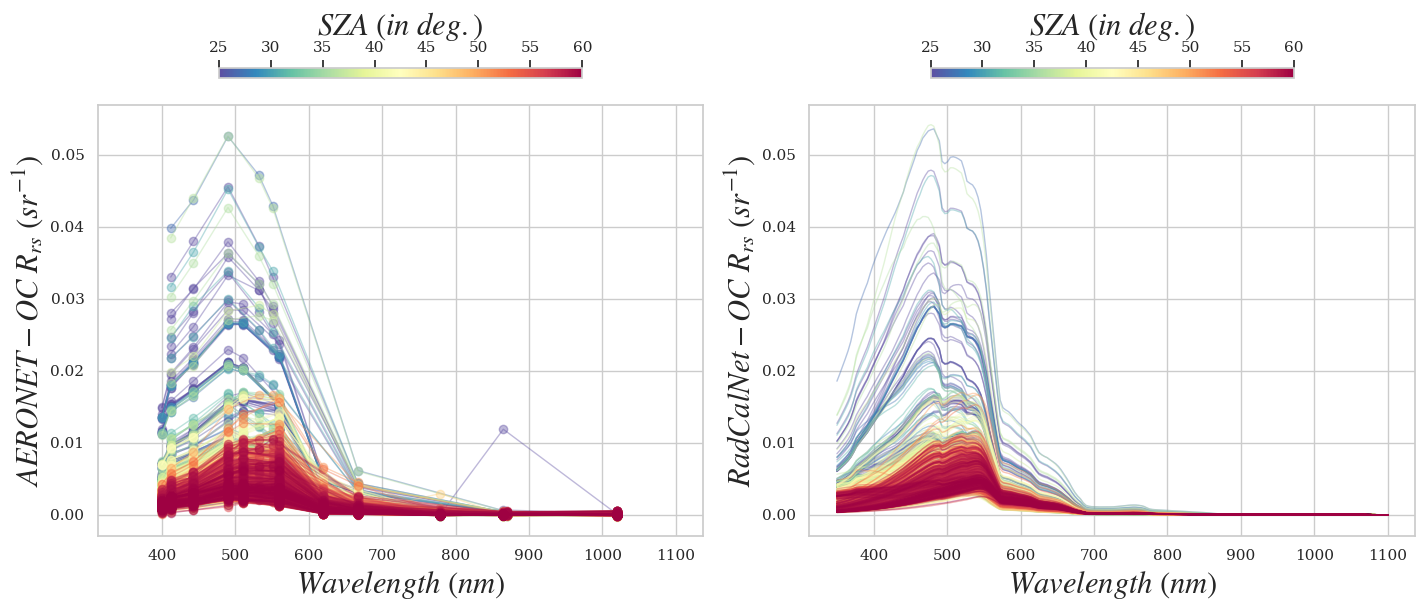

In [9]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=25, vmax=60)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig,axs = plt.subplots(1,2,figsize=(17,7),sharey='row',sharex=True)   
fig.subplots_adjust(hspace=0.25, wspace=0.175)
for sza,group in aeronet_oc_.where(aeronet_oc_.sza<60,drop=True).groupby('sza'):
    ii=1
    if sza <40:
        ii=0
    group['Rrs_Lwn'].dropna('wl_aeronet').plot(x='wl_aeronet',color=cmap(norm(sza)),lw=1,ls='-',marker='o',alpha=0.4,ax=axs[0])
    group['Rrs'].plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[1])
    #(group['Rrs_Lwn']).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[ii,1])

for ax in axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel('')
    ax.set_title('')
    ax.minorticks_on()
    
    ax.set_title('')

    cb = fig.colorbar(sm, ax=ax, shrink=0.6, aspect=35, pad=0.05, location='top')
    cb.set_label(r'$SZA\ (in\ deg.)$', fontsize=22)
    
axs[0].set_ylabel(r'$AERONET-OC\ R_{rs}\ (sr^{-1})$')

axs[1].yaxis.set_tick_params(labelleft=True)
axs[1].set_ylabel(r'$RadCalNet-OC\ R_{rs}\ (sr^{-1})$')    

plt.show()

/home/harmel/anaconda3/envs/py12/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4671: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


Text(0, 0.5, '$\\Delta R_{rs}\\ (sr^{-1})$')

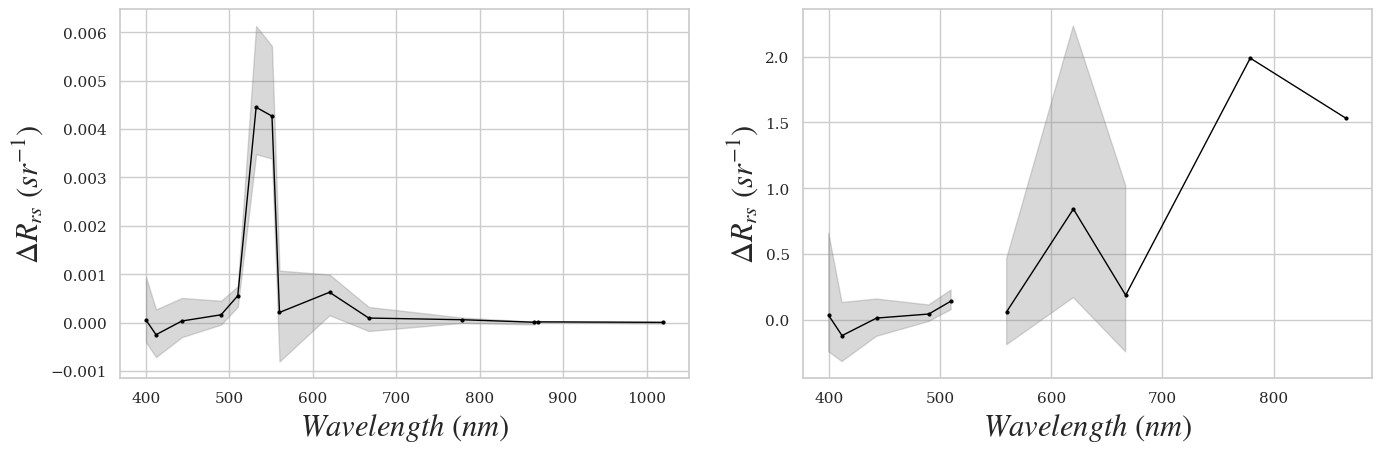

In [10]:

nrows=1
ncols=2
fig,axs = plt.subplots(nrows,ncols,figsize=(ncols*7,4.5*nrows)) 
fig.subplots_adjust(bottom=0.08, top=0.9, left=0.086, right=0.98,
                    hspace=0.5, wspace=0.2)
if (ncols == 1) & (nrows == 1):
    axs = np.array([axs])
axs_=axs
axs=axs.ravel()

# abs diff
ax=axs[0]
ds = delta_Rrs
avg=ds.median('time')
q20=ds.quantile(0.2,'time')
q80=ds.quantile(0.8,'time')
ax.minorticks_on()
avg.plot(color='black',marker='o',ms=2,ax=ax,lw=1) #,add_legend=False)
#(ds.reflectance/np.pi).plot(hue='time',ls=':',ax=ax,add_legend=False)
ax.fill_between(ds.wl, q20,q80,alpha=0.3,color='grey')
ax.set_ylabel('')
ax.set_xlabel(r'$Wavelength\ (nm)$')

#ax.set_ylim(0,0.004)
#ax.set_xlim(650,770)

ax.set_ylabel(r'$\Delta R_{rs}\ (sr^{-1})$')

# rel diff
ax=axs[1]
ds = delta_Rrs/aeronet_oc_.Rrs_Lwn_IOP
avg=ds.median('time')
q20=ds.quantile(0.2,'time')
q80=ds.quantile(0.8,'time')
ax.minorticks_on()
avg.plot(color='black',marker='o',ms=2,ax=ax,lw=1) #,add_legend=False)
#(ds.reflectance/np.pi).plot(hue='time',ls=':',ax=ax,add_legend=False)
ax.fill_between(ds.wl, q20,q80,alpha=0.3,color='grey')
ax.set_ylabel('')
ax.set_xlabel(r'$Wavelength\ (nm)$')

#ax.set_ylim(0,0.004)
#ax.set_xlim(650,770)

ax.set_ylabel(r'$\Delta R_{rs}\ (sr^{-1})$')



In [11]:
aeronet_oc_.Rrs_Lwn.interpolate_na('wl_aeronet')

<xarray.DataArray 'Rrs_Lwn' (time: 7586, wl_aeronet: 14)> Size: 850kB
array([[            nan,  6.79529621e-03,  9.72609611e-03, ...,
         9.25344362e-04,  8.42515472e-04,  1.18741943e-03],
       [            nan,  6.89159167e-03,  1.04280908e-02, ...,
         9.52062125e-04,  8.57033388e-04,  1.17515172e-03],
       [            nan,  7.34839017e-03,  1.03247812e-02, ...,
         7.88496814e-04,  6.95865880e-04,  8.74397115e-04],
       ...,
       [-8.73172418e-06,  2.21527203e-04,  6.87655266e-04, ...,
        -4.67347512e-05, -4.70736411e-05, -5.72403365e-05],
       [ 2.46294037e-04,  3.80405204e-04,  8.45068786e-04, ...,
         4.12741535e-05,  4.13682413e-05,  4.41908767e-05],
       [ 2.58497481e-04,  6.74783754e-04,  9.17598404e-04, ...,
         7.88275541e-05,  7.70802228e-05,  2.46602821e-05]],
      shape=(7586, 14))
Coordinates:
  * time        (time) datetime64[ns] 61kB 2017-01-02T08:22:55 ... 2023-01-01...
  * wl_aeronet  (wl_aeronet) float64 112B 400.0 412.0 443.0 ... 870.0 1.02e+03
Attributes:
    unit:         sr-1
    description:  remote sensing reflectance from AERONET-OC parameter Lwn wi...
    long name:    remote sensing reflectance from Lwn

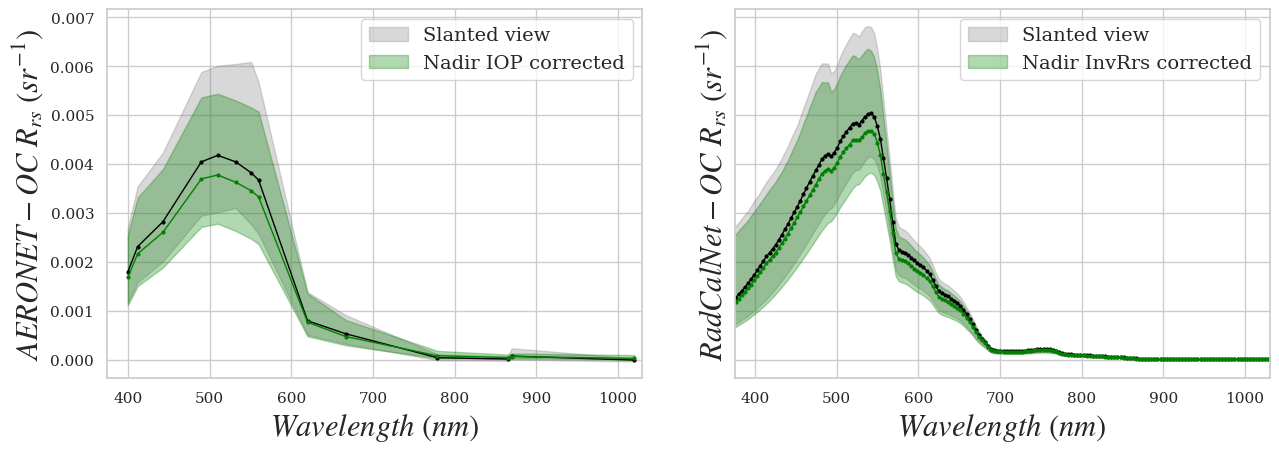

In [12]:

nrows=1
ncols=2
fig,axs = plt.subplots(nrows,ncols,figsize=(ncols*6.5,4.5*nrows),sharey=True,sharex=True) 
fig.subplots_adjust(bottom=0.08, top=0.9, left=0.086, right=0.98,
                    hspace=0.5, wspace=0.172)
if (ncols == 1) & (nrows == 1):
    axs = np.array([axs])
axs_=axs
axs=axs.ravel()

# abs diff
ax=axs[1]
ds = aeronet_oc_.Rrs
avg=ds.median('time')
q20=ds.quantile(0.2,'time')
q80=ds.quantile(0.8,'time')

avg.plot(color='black',marker='o',ms=2,ax=ax,lw=1) #,add_legend=False)
#(ds.reflectance/np.pi).plot(hue='time',ls=':',ax=ax,add_legend=False)
ax.fill_between(ds.wl, q20,q80,alpha=0.3,color='grey',label='Slanted view')

ds = aeronet_oc_.Rrs_nadir
avg=ds.median('time')
q20=ds.quantile(0.2,'time')
q80=ds.quantile(0.8,'time')

avg.plot(color='green',marker='o',ms=2,ax=ax,lw=1) #,add_legend=False)
#(ds.reflectance/np.pi).plot(hue='time',ls=':',ax=ax,add_legend=False)
ax.fill_between(ds.wl, q20,q80,alpha=0.3,color='green',label='Nadir InvRrs corrected')
ax.legend(fontsize=14)


ax.minorticks_on()
ax.set_ylabel('')
ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.minorticks_on()
#ax.set_ylim(0,0.004)
#ax.set_xlim(650,770)

ax.set_ylabel(r'$RadCalNet-OC\ R_{rs}\ (sr^{-1})$')

# rel diff
ax=axs[0]
ds = aeronet_oc_.Rrs_Lwn
avg=ds.median('time')
q20=ds.quantile(0.2,'time')
q80=ds.quantile(0.80,'time')
ax.minorticks_on()
avg.plot(color='black',marker='o',ms=2,ax=ax,lw=1) #,add_legend=False)
#(ds.reflectance/np.pi).plot(hue='time',ls=':',ax=ax,add_legend=False)
ax.fill_between(ds.wl_aeronet, q20,q80,alpha=0.3,color='grey',label='Slanted view')


ds = aeronet_oc_.Rrs_Lwn_IOP.where(aeronet_oc_.Rrs_Lwn_IOP>0,np.nan).interpolate_na('wl_aeronet')
avg=ds.median('time')
q20=ds.quantile(0.2,'time')
q80=ds.quantile(0.80,'time')
avg.plot(color='green',marker='o',ms=2,ax=ax,lw=1) #,add_legend=False)
#(ds.reflectance/np.pi).plot(hue='time',ls=':',ax=ax,add_legend=False)
ax.fill_between(ds.wl_aeronet, q20,q80,alpha=0.3,color='green',label='Nadir IOP corrected')

ax.legend(fontsize=14)
ax.set_ylabel('')
ax.set_xlabel(r'$Wavelength\ (nm)$')

#ax.set_ylim(0,0.004)
ax.set_xlim(375,1030)

ax.set_ylabel(r'$AERONET-OC\ R_{rs}\ (sr^{-1})$')
ax.minorticks_on()


In [13]:
# WARNING: interpolation here is because of a bug in the AERONET-OC database
# of GALATA with null values for the band between 500 and 600 nm
# or better drop band at 532 and 551 nm
#aeronet_oc_['Rrs_Lwn_IOP'] = aeronet_oc_.Rrs_Lwn_IOP.where(aeronet_oc_.Rrs_Lwn_IOP>0,np.nan).interpolate_na('wl_aeronet')
#aeronet_oc_ =aeronet_oc_.drop_sel(wl_aeronet=[532,551])

df=aeronet_oc_[['Rrs_nadir','Rrs_Lwn_IOP']].interp(wl=aeronet_oc_.wl_aeronet).drop_vars('wl').to_dataframe()#.unstack()
df.columns.name = 'var_name'

df=df.stack()
df.name = 'value'
df=df.reset_index(['wl_aeronet','var_name'])
df

,wl_aeronet,var_name,value
time,,,
2017-01-02 08:22:55,400.0,Rrs_nadir,0.005870
2017-01-02 08:22:55,400.0,Rrs_Lwn_IOP,0.000000
2017-01-02 08:22:55,412.0,Rrs_nadir,0.006900
2017-01-02 08:22:55,412.0,Rrs_Lwn_IOP,0.005839
2017-01-02 08:22:55,443.0,Rrs_nadir,0.010167
...,...,...,...
2023-01-01 10:54:49,865.0,Rrs_Lwn_IOP,0.000079
2023-01-01 10:54:49,870.0,Rrs_nadir,0.000017
2023-01-01 10:54:49,870.0,Rrs_Lwn_IOP,0.000000


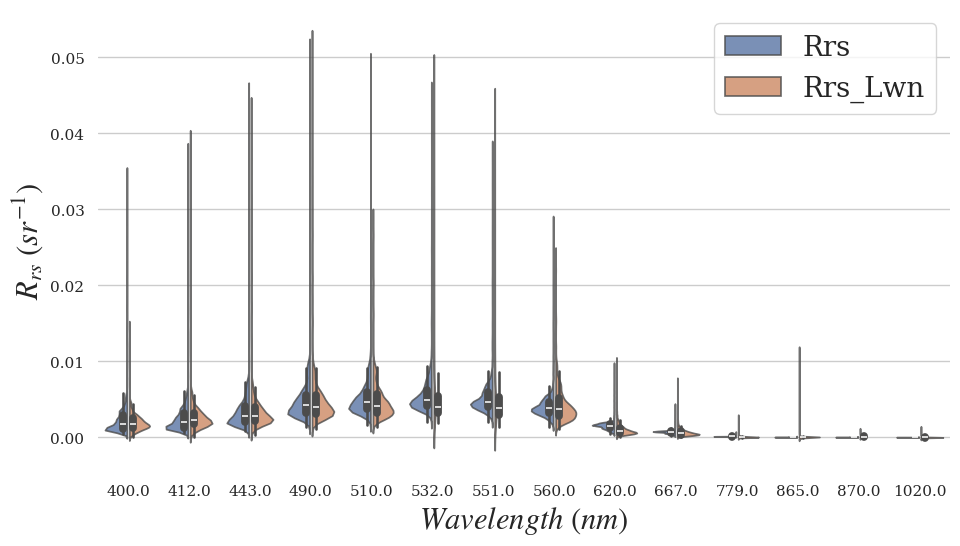

In [14]:

df=aeronet_oc_[['Rrs','Rrs_Lwn']].interp(wl=aeronet_oc_.wl_aeronet).drop_vars('wl').to_dataframe()#.unstack()
df.columns.name = 'var_name'

df=df.stack()
df.name = 'value'
df=df.reset_index(['wl_aeronet','var_name'])
#df=aeronet_oc_.Rrs_nadir.interp(wl=aeronet_oc_.wl_aeronet).drop_vars('wl').to_dataframe()#.unstack()
# Compute the correlation matrix and average over networks

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 6))

# Draw a violinplot with a narrower bandwidth than the default
sns.violinplot(data=df,x='wl_aeronet',y='value',hue='var_name',split=True,gap=.1,alpha=0.8, density_norm="count")#,bw_adjust=.5)#, cut=0.4, linewidth=1, palette="rainbow")#, native_scale=True

# Finalize the figure
#ax.set(ylim=(-.7, 1.05))
sns.despine(left=True, bottom=True)
ax.set_xlabel(r'$Wavelength\ (nm)$')

#ax.set_ylim(0,0.004)
#ax.set_xlim(650,770)

ax.set_ylabel(r'$R_{rs}\ (sr^{-1})$')
plt.legend(fontsize='20')

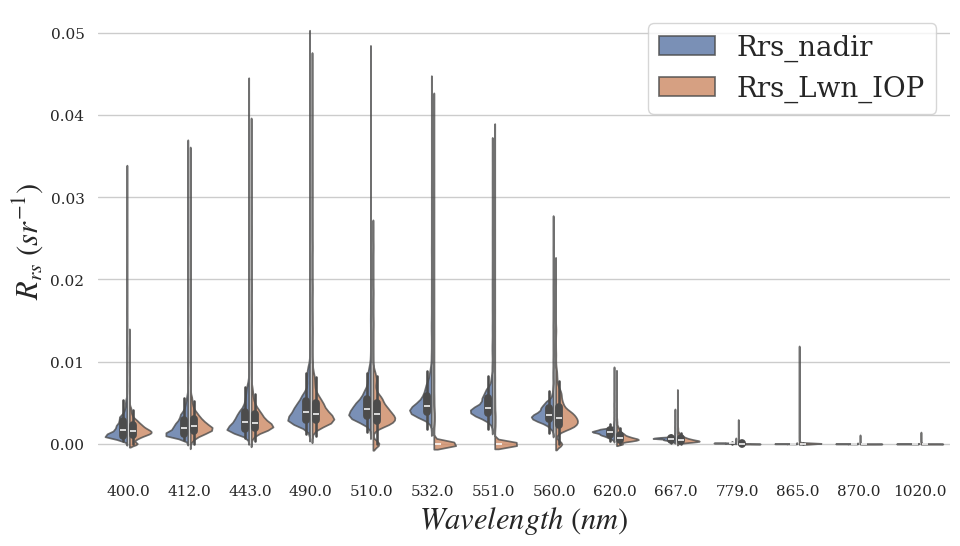

In [15]:

df=aeronet_oc_[['Rrs_nadir','Rrs_Lwn_IOP']].interp(wl=aeronet_oc_.wl_aeronet).drop_vars('wl').to_dataframe()#.unstack()
df.columns.name = 'var_name'

df=df.stack()
df.name = 'value'
df=df.reset_index(['wl_aeronet','var_name'])
#df=aeronet_oc_.Rrs_nadir.interp(wl=aeronet_oc_.wl_aeronet).drop_vars('wl').to_dataframe()#.unstack()
# Compute the correlation matrix and average over networks

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 6))

# Draw a violinplot with a narrower bandwidth than the default
sns.violinplot(data=df,x='wl_aeronet',y='value',hue='var_name',split=True,gap=.1,alpha=0.8, density_norm="count")#,bw_adjust=.001)#, cut=0.4, linewidth=1, palette="rainbow")#, native_scale=True

# Finalize the figure
#ax.set(ylim=(-.7, 1.05))
sns.despine(left=True, bottom=True)
ax.set_xlabel(r'$Wavelength\ (nm)$')

#ax.set_ylim(0,0.004)
#ax.set_xlim(650,770)

ax.set_ylabel(r'$R_{rs}\ (sr^{-1})$')
plt.legend(fontsize='20')

/tmp/ipykernel_1853390/90273623.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df[np.abs(df)<0.004],x='wl_aeronet',y='delta_Rrs',bw_adjust=0.5321, cut=0.004, linewidth=1, palette="rainbow")#, native_scale=True


Text(0, 0.5, '$\\Delta R_{rs}\\ (sr^{-1})$')

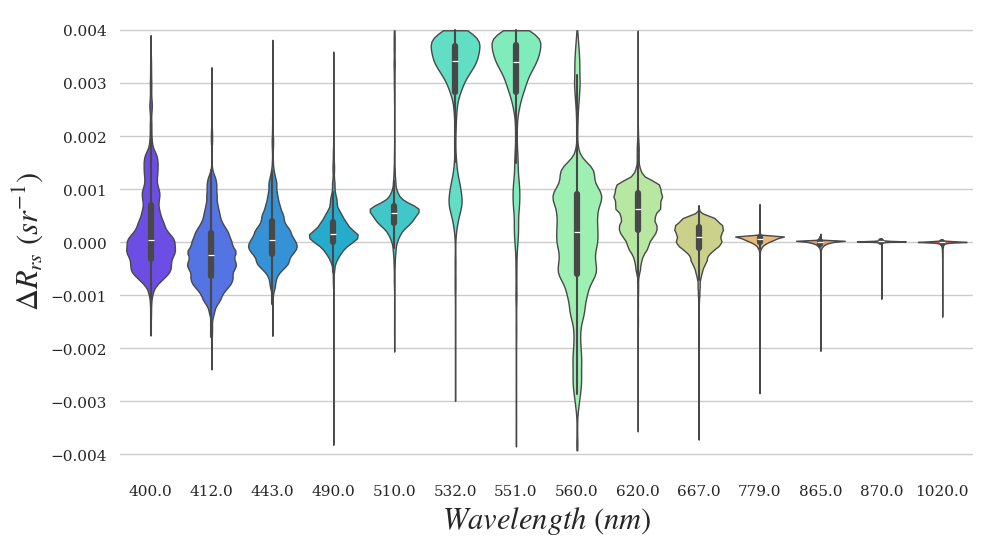

In [16]:
delta_Rrs = aeronet_oc_.Rrs_nadir.interp(wl=aeronet_oc_.wl_aeronet) - aeronet_oc_.Rrs_Lwn_IOP
delta_Rrs.name='delta_Rrs'

df=delta_Rrs.drop_vars('wl').to_dataframe()#.unstack()

# Compute the correlation matrix and average over networks

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 6))

# Draw a violinplot with a narrower bandwidth than the default
sns.violinplot(data=df[np.abs(df)<0.004],x='wl_aeronet',y='delta_Rrs',bw_adjust=0.5321, cut=0.004, linewidth=1, palette="rainbow")#, native_scale=True

# Finalize the figure
#ax.set(ylim=(-.7, 1.05))
sns.despine(left=True, bottom=True)
ax.set_xlabel(r'$Wavelength\ (nm)$')

#ax.set_ylim(0,0.004)
#ax.set_xlim(650,770)

ax.set_ylabel(r'$\Delta R_{rs}\ (sr^{-1})$')


In [17]:
df

delta_Rrs
time                wl_aeronet           
2017-01-02 08:22:55 400.0        0.005870
                    412.0        0.001061
                    443.0        0.001807
                    490.0        0.001633
                    510.0        0.015185
...                                   ...
2023-01-01 10:54:49 667.0        0.000247
                    779.0        0.000003
                    865.0       -0.000057
                    870.0        0.000017
                    1020.0      -0.000015

[106204 rows x 1 columns]

### Check uncertainty propagation

In [18]:
ds = aeronet_oc_.isel(time=[162,163])
ds

<xarray.Dataset> Size: 9kB
Dimensions:      (time: 2, wl_aeronet: 14, wl: 200)
Coordinates:
  * time         (time) datetime64[ns] 16B 2017-08-10T07:46:13 2017-08-10T09:...
  * wl_aeronet   (wl_aeronet) float64 112B 400.0 412.0 443.0 ... 870.0 1.02e+03
  * wl           (wl) float64 2kB 350.0 353.8 357.5 ... 1.096e+03 1.1e+03
Data variables: (12/15)
    tcwv         (time) float64 16B 21.93 24.59
    tco3         (time) float64 16B 0.006744 0.006744
    tcno2        (time) float64 16B 4.215e-06 4.214e-06
    pressure     (time) float64 16B 1.013e+03 1.013e+03
    sza          (time) float64 16B 41.45 28.12
    day_of_year  (time) int64 16B 222 222
    ...           ...
    naot         (time, wl_aeronet) float64 224B nan 1.604 1.433 ... 0.46 0.3429
    Rrs_Lwn      (time, wl_aeronet) float64 224B nan 0.005688 ... 9.965e-06
    Rrs_Lwn_IOP  (time, wl_aeronet) float64 224B 0.0 0.005215 ... 0.0 9.965e-06
    Rrs_Lwn_fQ   (time, wl_aeronet) float64 224B nan 0.005556 ... 9.965e-06
    Rrs          (time, wl) float64 3kB 0.003261 0.003394 0.003536 ... 0.0 0.0
    Rrs_nadir    (time, wl) float64 3kB 0.003044 0.003168 0.003301 ... 0.0 0.0

INFO:root:get LUT object
INFO:root:loading look-up tables
INFO:root:get auxiliary data
INFO:root:loading look-up tables
INFO:root:get solar irradiance
INFO:root:get gaseous transmittance object
INFO:root:set input parameters
INFO:root:LUT preparation
INFO:root:get LUT object
INFO:root:loading look-up tables
INFO:root:get auxiliary data
INFO:root:loading look-up tables
INFO:root:get solar irradiance
INFO:root:get gaseous transmittance object
INFO:root:set input parameters
INFO:root:LUT preparation
INFO:root:get LUT object
INFO:root:loading look-up tables
INFO:root:get auxiliary data
INFO:root:loading look-up tables
INFO:root:get solar irradiance
INFO:root:get gaseous transmittance object
INFO:root:set input parameters
INFO:root:LUT preparation
INFO:root:get LUT object
INFO:root:loading look-up tables
INFO:root:get auxiliary data
INFO:root:loading look-up tables
INFO:root:get solar irradiance
INFO:root:get gaseous transmittance object
INFO:root:set input parameters
INFO:root:LUT preparat

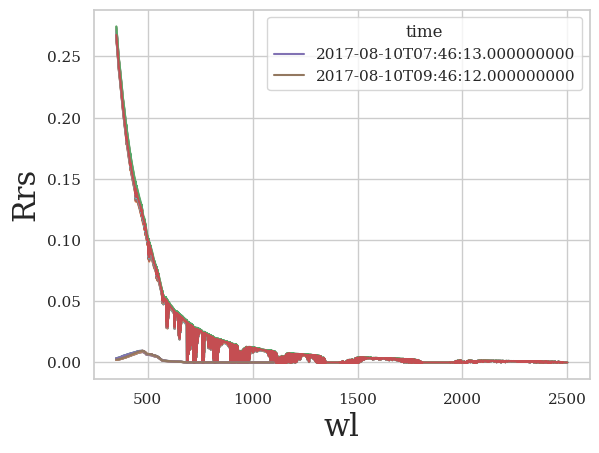

In [19]:
Rrs = ds.Rrs
naot = ds.naot.dropna('wl_aeronet',how='all')
Rtoas = []
for aot550 in [0.19,0.2,0.21]:
    Rtoa_ = []
    for rel_err_Rrs in [0.95,1,1.05]:
        ds['aot550']=aot550
        ds['Rrs']=Rrs*rel_err_Rrs
        radoc_process = radoc.Process(ds)    
        aero_process = radoc.Aerosol(naot,radoc_process.lut.naot_lut)
        aero_process.process()
        model =aero_process.model_db
        ds = xr.merge([ds,model])
        radoc_process.execute(aerosol_combination=model.aerosol_combination)
        radoc_process.radcalnet_db.Rtoa.plot(hue ='time')
        radoc_process.Rrs.plot(hue ='time')
        Rtoa_.append(radoc_process.radcalnet_db.Rtoa.assign_coords({'rel_err_Rrs':rel_err_Rrs}))
    Rtoas.append(xr.concat(Rtoa_,'rel_err_Rrs'))

In [20]:
radoc_process.radcalnet_db.Rtoa

<xarray.DataArray 'Rtoa' (wl: 21532, time: 2)> Size: 345kB
array([[2.74532353e-01, 2.67577343e-01],
       [2.74192968e-01, 2.67226925e-01],
       [2.73832668e-01, 2.66857888e-01],
       ...,
       [6.48530716e-09, 4.50293896e-09],
       [1.91635222e-09, 1.29066557e-09],
       [2.15780748e-06, 1.73126952e-06]], shape=(21532, 2))
Coordinates:
  * time     (time) datetime64[ns] 16B 2017-08-10T07:46:13 2017-08-10T09:46:12
  * wl       (wl) float64 172kB 350.1 350.3 350.5 ... 2.499e+03 2.5e+03
    aot_ref  float64 8B 0.21
    vza      int64 8B 0
    sza      (time) float64 16B 41.45 28.12
Attributes:
    unit:         -
    description:  Total reflectance at top-of-atmosphere

In [21]:
deltaRtoa = xr.concat(Rtoas,'aot_ref')
deltaRtoa

<xarray.DataArray 'Rtoa' (aot_ref: 3, rel_err_Rrs: 3, wl: 21532, time: 2)> Size: 3MB
array([[[[2.71491395e-01, 2.64856616e-01],
         [2.71148882e-01, 2.64503638e-01],
         [2.70785686e-01, 2.64132228e-01],
         ...,
         [5.91556594e-09, 4.10854568e-09],
         [1.74800073e-09, 1.17762327e-09],
         [1.96824658e-06, 1.57963933e-06]],

        [[2.71734247e-01, 2.65030777e-01],
         [2.71392543e-01, 2.64678424e-01],
         [2.71030140e-01, 2.64307629e-01],
         ...,
         [5.91556594e-09, 4.10854568e-09],
         [1.74800073e-09, 1.17762327e-09],
         [1.96824658e-06, 1.57963933e-06]],

        [[2.71977098e-01, 2.65204938e-01],
         [2.71636205e-01, 2.64853210e-01],
         [2.71274594e-01, 2.64483029e-01],
         ...,
...
         ...,
         [6.48530716e-09, 4.50293896e-09],
         [1.91635222e-09, 1.29066557e-09],
         [2.15780748e-06, 1.73126952e-06]],

        [[2.74292742e-01, 2.67405292e-01],
         [2.73952556e-01, 2.67054255e-01],
         [2.73591472e-01, 2.66684609e-01],
         ...,
         [6.48530716e-09, 4.50293896e-09],
         [1.91635222e-09, 1.29066557e-09],
         [2.15780748e-06, 1.73126952e-06]],

        [[2.74532353e-01, 2.67577343e-01],
         [2.74192968e-01, 2.67226925e-01],
         [2.73832668e-01, 2.66857888e-01],
         ...,
         [6.48530716e-09, 4.50293896e-09],
         [1.91635222e-09, 1.29066557e-09],
         [2.15780748e-06, 1.73126952e-06]]]], shape=(3, 3, 21532, 2))
Coordinates:
  * time         (time) datetime64[ns] 16B 2017-08-10T07:46:13 2017-08-10T09:...
  * wl           (wl) float64 172kB 350.1 350.3 350.5 ... 2.499e+03 2.5e+03
  * aot_ref      (aot_ref) float64 24B 0.19 0.2 0.21
    vza          int64 8B 0
    sza          (time) float64 16B 41.45 28.12
  * rel_err_Rrs  (rel_err_Rrs) float64 24B 0.95 1.0 1.05
Attributes:
    unit:         -
    description:  Total reflectance at top-of-atmosphere

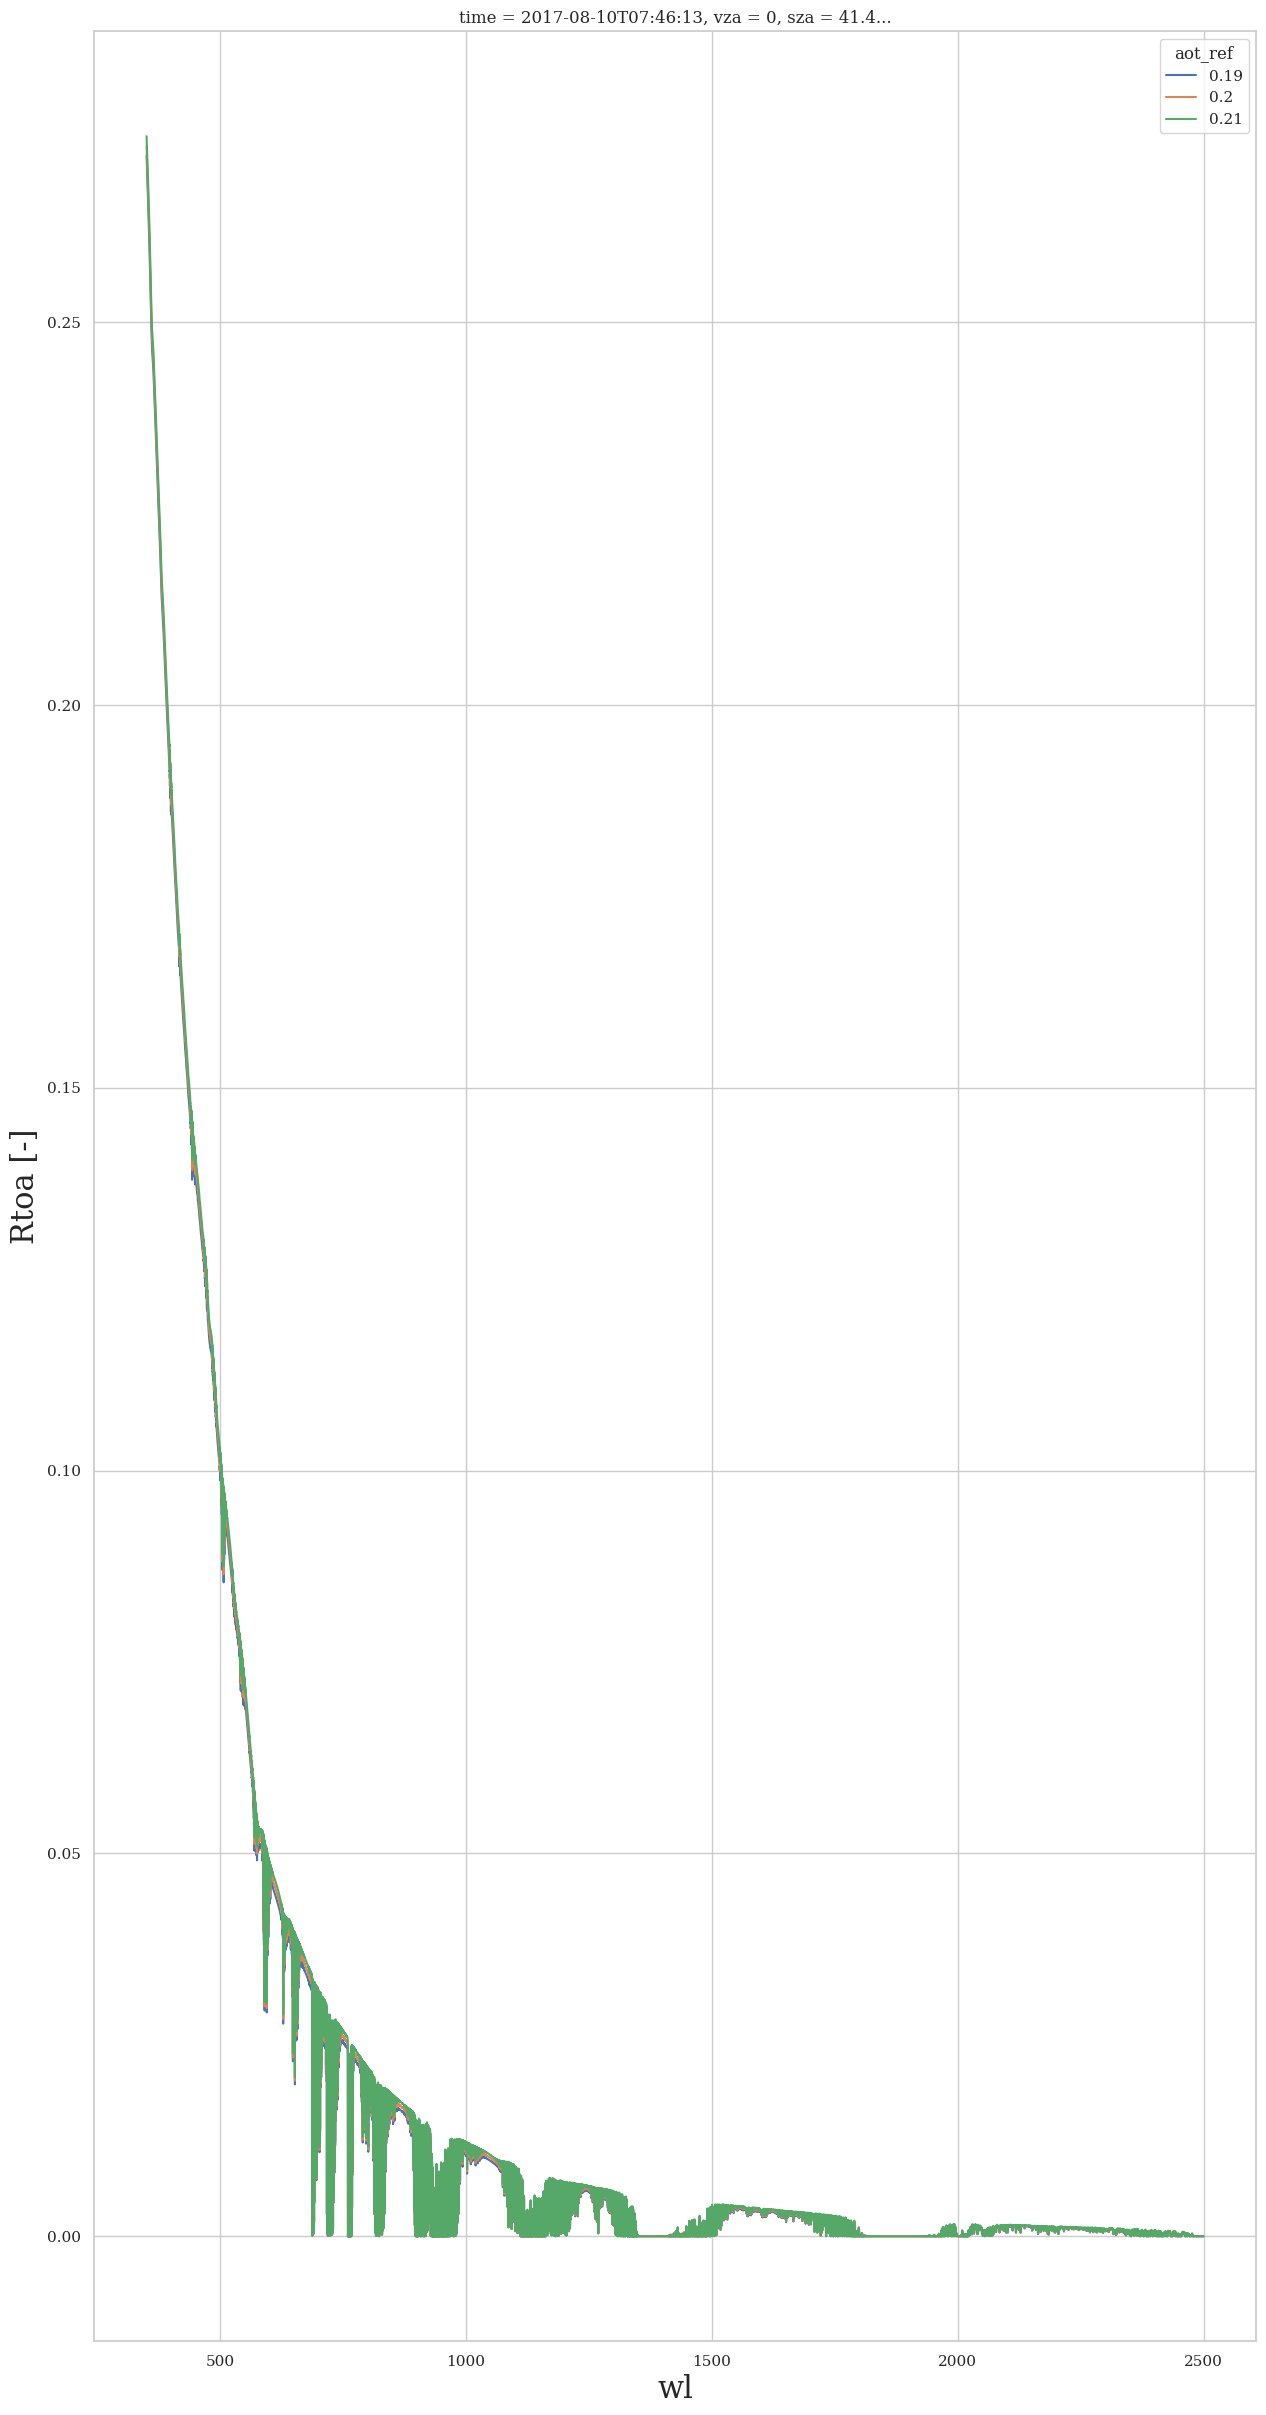

In [22]:
plt.figure(figsize=(15,30))
deltaRtoa.isel(time=0,rel_err_Rrs=1).plot(hue='aot_ref')

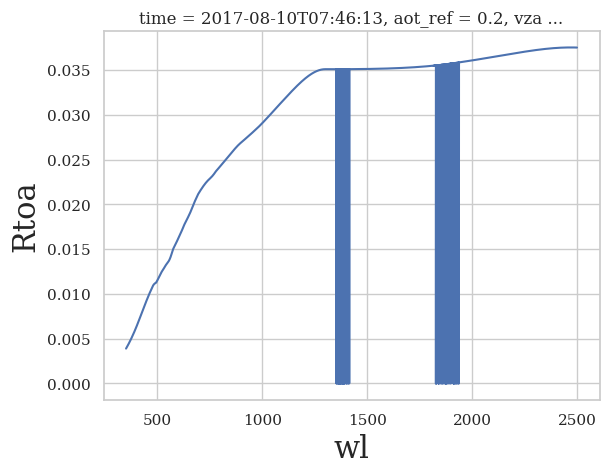

In [23]:
Rtoa_Rrs_std = deltaRtoa.isel(aot_ref=1).std('rel_err_Rrs')
Rtoa_Rrs_avg = deltaRtoa.isel(aot_ref=1).mean('rel_err_Rrs')
Rtoa_aot_std = deltaRtoa.isel(rel_err_Rrs=1).std('aot_ref')
Rtoa_aot_avg = deltaRtoa.isel(rel_err_Rrs=1).mean('aot_ref')
Rtoa_avg= deltaRtoa.mean('rel_err_Rrs').mean('aot_ref')
np.sqrt(((Rtoa_Rrs_std/Rtoa_Rrs_avg)**2+(Rtoa_aot_std/Rtoa_aot_avg)**2)).isel(time=0).plot()

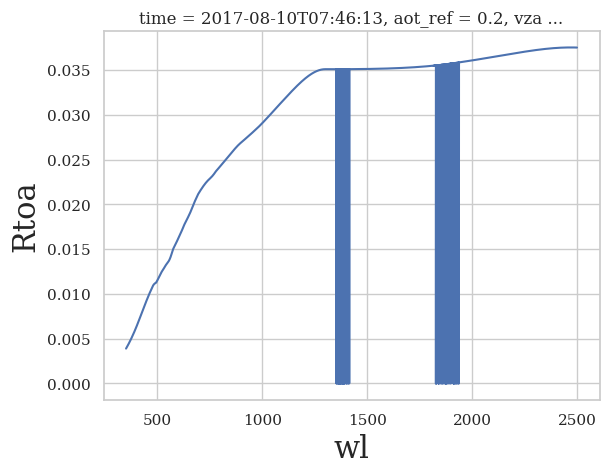

In [36]:
Rtoa_Rrs_std = deltaRtoa.isel(aot_ref=1).std('rel_err_Rrs')
Rtoa_Rrs_avg = deltaRtoa.isel(aot_ref=1).mean('rel_err_Rrs')
Rtoa_aot_std = deltaRtoa.isel(rel_err_Rrs=1).std('aot_ref')
Rtoa_aot_avg = deltaRtoa.isel(rel_err_Rrs=1).mean('aot_ref')
Rtoa_avg= deltaRtoa.mean('rel_err_Rrs').mean('aot_ref')
uncertainty = np.sqrt(((Rtoa_Rrs_std/Rtoa_Rrs_avg)**2+(Rtoa_aot_std/Rtoa_aot_avg)**2)).isel(time=0)
uncertainty.plot()
uncertainty.reset_coords(drop=True).to_dataframe().to_csv('/DATA/projet/magellium/radcalnet/data/Rtoa_rel_uncertainty.csv')


Text(0.5, 1.0, '')

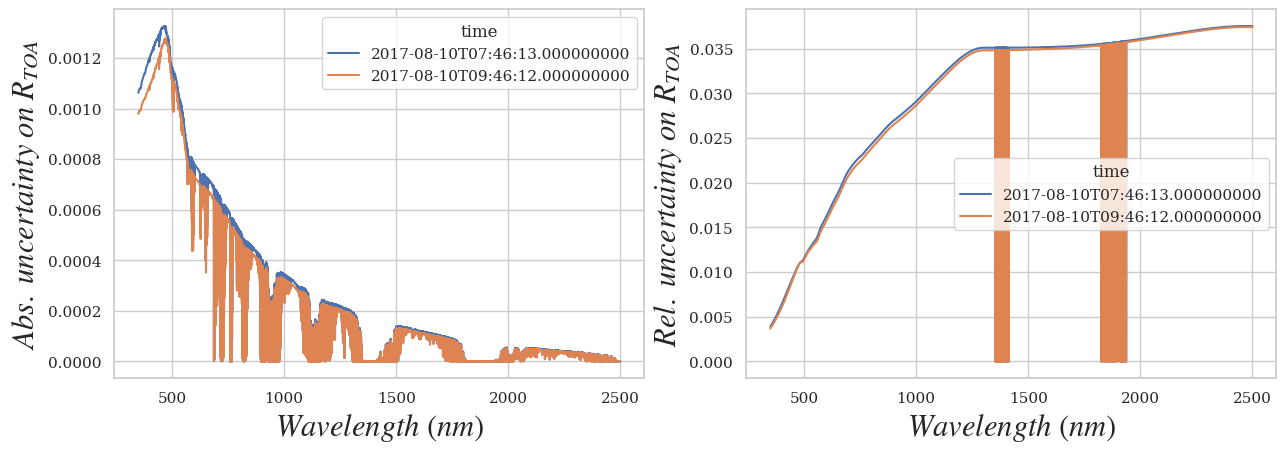

In [25]:

nrows=1
ncols=2
fig,axs = plt.subplots(nrows,ncols,figsize=(ncols*6.5,4.5*nrows),sharex=True) 
fig.subplots_adjust(bottom=0.08, top=0.9, left=0.086, right=0.98,
                    hspace=0.5, wspace=0.192)
if (ncols == 1) & (nrows == 1):
    axs = np.array([axs])
axs_=axs
axs=axs.ravel()

# abs diff
ax=axs[0]
(Rtoa_avg*np.sqrt(((Rtoa_Rrs_std/Rtoa_Rrs_avg)**2+(Rtoa_aot_std/Rtoa_aot_avg)**2))).plot(hue='time',ax=ax)
ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.set_ylabel(r'$Abs.\ uncertainty\ on\ R_{TOA}$')
ax.set_title('')
ax=axs[1]
np.sqrt(((Rtoa_Rrs_std/Rtoa_Rrs_avg)**2+(Rtoa_aot_std/Rtoa_aot_avg)**2)).plot(hue='time',ax=ax)#.isel(time=0).plot(ax=ax)
ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.set_ylabel(r'$Rel.\ uncertainty\ on\ R_{TOA}$')
ax.set_title('')

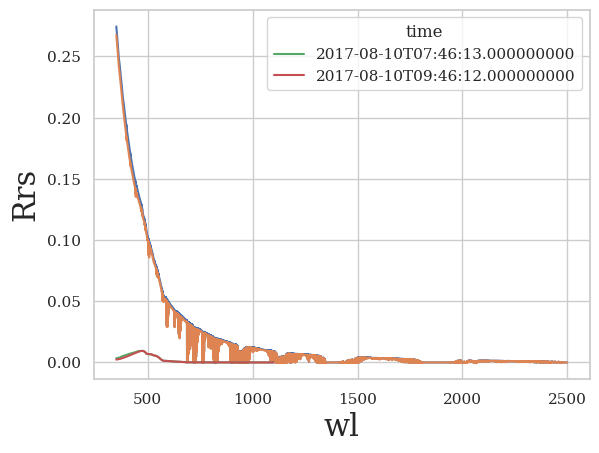

In [26]:
radoc_process.radcalnet_db.Rtoa.plot(hue ='time')
radoc_process.Rrs.plot(hue ='time')

### Check AERONET aerosol products

In [27]:
aeronet_oc_ = aeronet_oc.sel(time=slice('2021-05-01','2021-05-03'))
radoc_process = radoc.Process(aeronet_oc_,Rrs_name='Rrs_Lwn')
radoc_process.lut_preparation()
radoc_process.F0.plot(lw=0.3)

INFO:root:get LUT object
INFO:root:loading look-up tables
INFO:root:get auxiliary data
INFO:root:loading look-up tables
INFO:root:get solar irradiance
INFO:root:get gaseous transmittance object
INFO:root:set input parameters
INFO:root:LUT preparation


ValueError: zero-size array to reduction operation fmin which has no identity

In [ ]:
radoc_process.get_downwelling_irradiance(aerosol_combination=[0, 0.5, 0.5, 0., 0.0])
Ed = radoc_process.Ed
fwhm=15
central_wl = aeronet_oc.wavelength.mean('time')*1000
spectral=radoc.Spectral(central_wl,fwhm)
Ed_int = spectral.convolve2(Ed,expon=5).to_dataarray()
#Ed_int['sza']=Ed.sza
Ed_int['wl']=aeronet_oc.wl
Ed_int=Ed_int.squeeze()

In [ ]:
radoc_process.lut.trans_aero_lut#Tra_d.isel(time=0).plot()

In [ ]:
aeronet_oc_['Rrs_radoc'] = (10*aeronet_oc_.Lw/Ed_int).reset_coords(drop=True)

In [ ]:
radoc_process.lut.trans_aero_lut.interp(sza=radoc_process.sza,
                                                    aot_ref=radoc_process.aot550
                                                    ).interpolate_na('time').interp(wl=np.linspace(350,2500,100), method='cubic')#.interp(wl=radoc_process.full_wl)#, method='quadratic')

In [ ]:
aeronet_oc_

In [ ]:
data = aeronet_oc_.isel(time=slice(200,250))
print(list(data.keys()))

In [ ]:
data[[ 'tcwv', 'tco3', 'tcno2', 'pressure', 'sza', 'day_of_year', 'aot550', 'aot865', 'ang_exp']]

In [ ]:
data=data[[ 'tcwv', 'tco3', 'tcno2', 'pressure', 'sza', 'day_of_year', 'aot550', 'aot865', 'ang_exp']]
data.to_netcdf('../radcalnet_oc/data/template/template.nc')

In [ ]:
import yaml



data = aeronet_oc_.isel(time=0).to_dict()

with open('data.yml', 'w') as outfile:
    yaml.dump(data, outfile, default_flow_style=False)

In [ ]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=1010, vmax=1030)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig,axs = plt.subplots(2,2,figsize=(15,15),sharey='row')#,sharex=True)   
fig.subplots_adjust(hspace=0.25, wspace=0.05)
for sza,group in aeronet_oc_.where(aeronet_oc_.sza<60,drop=True).groupby('sza'):
    ii=1
    if sza <40:
        ii=0
    color=group.pressure.values
    group['Rrs_radoc'].plot(x='wl',color=cmap(norm(color)),lw=1,ls='-',alpha=0.4,ax=axs[ii,0])
    (group['Rrs_Lwn']).plot(x='wl',color=cmap(norm(color)),lw=1,ls='-',alpha=0.4,ax=axs[ii,1])

for ax in  axs.ravel():
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel('')
    ax.set_title('')
    ax.minorticks_on()

axs[0,0].set_title('With Radcalnet-oc Ed')
axs[0,1].set_title('With Aeronet-oc Ed')

axs[0,0].set_ylabel(r'$R_{rs}\ (sr^{-1})$')
axs[1,0].set_ylabel(r'$R_{rs}\ (sr^{-1})$')

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.05, location='top')
cb.set_label(r'$SZA\ (in\ deg.)$', fontsize=22)
plt.show()

In [ ]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=25, vmax=60)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig,axs = plt.subplots(2,2,figsize=(15,15),sharey='row')#,sharex=True)   
fig.subplots_adjust(hspace=0.25, wspace=0.05)
for sza,group in aeronet_oc_.where(aeronet_oc_.sza<60,drop=True).groupby('sza'):
    ii=1
    if sza <40:
        ii=0
    group['Rrs_radoc'].plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[ii,0])
    (group['Rrs_Lwn']).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[ii,1])

for ax in  axs.ravel():
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel('')
    ax.set_title('')
    ax.minorticks_on()

axs[0,0].set_title('With Radcalnet-oc Ed')
axs[0,1].set_title('With Aeronet-oc Ed')

axs[0,0].set_ylabel(r'$R_{rs}\ (sr^{-1})$')
axs[1,0].set_ylabel(r'$R_{rs}\ (sr^{-1})$')

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.05, location='top')
cb.set_label(r'$SZA\ (in\ deg.)$', fontsize=22)
plt.show()

In [ ]:
aeronet_oc_

In [ ]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=25, vmax=60)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig,ax = plt.subplots(1,1,figsize=(8,7),sharey='row')#,sharex=True)   
fig.subplots_adjust(hspace=0.25, wspace=0.05)
for sza,group in aeronet_oc_.where(aeronet_oc_.sza<60,drop=True).groupby('sza'):
    ii=1
    if sza <40:
        ii=0
    group['Rrs_radoc'].plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',marker='o',alpha=0.4,ax=ax)
    #(group['Rrs_Lwn']).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[ii,1])


ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.set_ylabel('')
ax.set_title('')
ax.minorticks_on()

ax.set_title('')

ax.set_ylabel(r'$R_{rs}\ (sr^{-1})$')

cb = fig.colorbar(sm, ax=ax, shrink=0.6, aspect=35, pad=0.05, location='top')
cb.set_label(r'$SZA\ (in\ deg.)$', fontsize=22)
plt.show()

In [ ]:
hyp_aeronet_oc = xr.open_mfdataset('/DATA/AERONET/OCv3_invRrs/data/Venise/lev20/Venise_lev20_*')
dates=aeronet_oc_.where(aeronet_oc_.sza<60,drop=True).time
hyp_aeronet_oc_=hyp_aeronet_oc.sel(time=dates)
aeronet_oc__ = aeronet_oc_[['tcwv', 'tco3', 'tcno2', 'pressure', 'sza', 'day_of_year', 'aot550', 'aot865', 'ang_exp']]
xtemp= xr.merge([aeronet_oc__,hyp_aeronet_oc_])

cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=25, vmax=60)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig,ax = plt.subplots(1,1,figsize=(8,7),sharey='row')#,sharex=True)   
fig.subplots_adjust(hspace=0.25, wspace=0.05)
for sza,group in xtemp.where(aeronet_oc_.sza<60,drop=True).groupby('sza'):
    ii=1
    if sza <40:
        ii=0
    group['Rrs'].plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.74,ax=ax)
    #(group['Rrs_Lwn']).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[ii,1])


ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.set_ylabel('')
ax.set_title('')
ax.minorticks_on()

ax.set_title('')

ax.set_ylabel(r'$R_{rs}\ (sr^{-1})$')

cb = fig.colorbar(sm, ax=ax, shrink=0.6, aspect=35, pad=0.05, location='top')
cb.set_label(r'$SZA\ (in\ deg.)$', fontsize=22)
plt.show()

In [ ]:
aeronet_oc_

In [ ]:
radoc_process.get_downwelling_irradiance(aerosol_combination=[0, 0.5, 0.5, 0., 0.0])
Ed = radoc_process.Ed
Ed.sel(time=xtemp.time)

In [ ]:
xtemp

In [ ]:
hyp_aeronet_oc = xr.open_mfdataset('/DATA/AERONET/OCv3_invRrs/data/Venise/lev20/Venise_lev20_*')
dates=aeronet_oc_.where(aeronet_oc_.sza<60,drop=True).time
hyp_aeronet_oc_=hyp_aeronet_oc.sel(time=dates)
aeronet_oc__ = aeronet_oc_[['Rrs_radoc','tcwv', 'tco3', 'tcno2', 'pressure', 'sza', 'day_of_year', 'aot550', 'aot865', 'ang_exp']].where(aeronet_oc_.sza<60,drop=True)
xtemp= xr.merge([aeronet_oc_.sza,hyp_aeronet_oc_]).load()#xr.merge([aeronet_oc__,hyp_aeronet_oc_])


cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=25, vmax=60)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig,ax = plt.subplots(1,1,figsize=(8,7),sharey='row')#,sharex=True)   
fig.subplots_adjust(hspace=0.25, wspace=0.05)
for date,group in xtemp.groupby('time'):
    ii=1
    sza = float(group.sza.values)
    if sza <40:
        ii=0
    Ed_=Ed.sel(time=group.time.values).sel(wl=slice(380,1100))    
    (group['Rrs'].interp(wl=Ed_.wl.values)*Ed_).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.74,ax=ax)
    #(group['Rrs_Lwn']).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[ii,1])


ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.set_ylabel('')
ax.set_title('')
ax.minorticks_on()

ax.set_title('')

ax.set_ylabel(r'$L_{w}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
cb = fig.colorbar(sm, ax=ax, shrink=0.6, aspect=35, pad=0.05, location='top')
cb.set_label(r'$SZA\ (in\ deg.)$', fontsize=22)
plt.show()

In [ ]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=25, vmax=60)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)


aeronet_oc_['delta_Rrs']=(aeronet_oc_['Rrs_radoc']-aeronet_oc_['Rrs_Lwn'])
aeronet_oc_['delta_rel_Rrs']=aeronet_oc_['delta_Rrs']/aeronet_oc_['Rrs_Lwn']




fig,axs = plt.subplots(2,2,figsize=(17,14),sharex=True)   
fig.subplots_adjust(hspace=0.25, wspace=0.3)
for sza,group in aeronet_oc_.where(aeronet_oc_.sza<65,drop=True).groupby('sza'):
    ii=1
    if sza <40:
        ii=0
    group['delta_Rrs'].plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[ii,0])
    (group['delta_rel_Rrs']).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[ii,1])
    
for ax in  axs.ravel():
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel('')
    ax.set_title('')
    ax.minorticks_on() 
for ii in range(2):
    axs[ii,0].set_ylabel(r'$R_{rs}^{radoc}-R_{rs}^{aeronet-oc}\ (sr^{-1})$')
    axs[ii,1].set_ylabel(r'$\Delta R_{rs}/R_{rs}^{aeronet-oc}$')
ax=axs[0,0]
ax.text(1.1, 1.1, r'$SZA <40\degree$', fontsize=24, verticalalignment='top', horizontalalignment='center',
                transform=ax.transAxes)
ax=axs[1,0]
ax.text(1.1, 1.1, r'$SZA \geq40\degree$', fontsize=24, verticalalignment='top', horizontalalignment='center',
                transform=ax.transAxes)
cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.05, location='top')
cb.set_label(r'$SZA\ (in\ deg.)$', fontsize=22)
plt.show()

In [ ]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=0, vmax=0.5)
norm = mpl.colors.Normalize(vmin=1010, vmax=1030)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)






fig,axs = plt.subplots(2,2,figsize=(17,14),sharex=True)   
fig.subplots_adjust(hspace=0.25, wspace=0.3)
for sza,group in aeronet_oc_.where(aeronet_oc_.sza<65,drop=True).groupby('sza'):
    ii=1
    if sza <40:
        ii=0
    color=group.aot550.values
    color=group.pressure.values
    group['delta_Rrs'].plot(x='wl',color=cmap(norm(color)),lw=1,ls='-',alpha=0.4,ax=axs[ii,0])
    (group['delta_rel_Rrs']).plot(x='wl',color=cmap(norm(color)),lw=1,ls='-',alpha=0.4,ax=axs[ii,1])
    
for ax in  axs.ravel():
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel('')
    ax.set_title('')
    ax.minorticks_on() 
for ii in range(2):
    axs[ii,0].set_ylabel(r'$R_{rs}^{radoc}-R_{rs}^{aeronet-oc}\ (sr^{-1})$')
    axs[ii,1].set_ylabel(r'$\Delta R_{rs}/R_{rs}^{aeronet-oc}$')
ax=axs[0,0]
ax.text(1.1, 1.1, r'$SZA <40\degree$', fontsize=24, verticalalignment='top', horizontalalignment='center',
                transform=ax.transAxes)
ax=axs[1,0]
ax.text(1.1, 1.1, r'$SZA \geq40\degree$', fontsize=24, verticalalignment='top', horizontalalignment='center',
                transform=ax.transAxes)
cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.05, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)
plt.show()

In [ ]:
owt_file = '/DATA/projet/vrac/owt/Spyrakos_et_al_2018_OWT_inland_mean_standardised.csv'
owt =pd.read_csv(owt_file,index_col=0).stack().to_xarray()
owt = owt.rename({'level_1':'wl'})
owt['wl']=owt.wl.astype(float)
owt

In [ ]:

import matplotlib.patches as mpatches

owt_info={
        1:dict(color='olivedrab',label='OWT1: Hypereutrophic waters'),
        2:dict(color='black',label='OWT2: Common case waters'),
        3:dict(color='cadetblue',label='OWT3: Clear waters'),
        4:dict(color='tan',label='OWT4: Turbid waters with organic content'),
        5:dict(color='chocolate',label='OWT5: Sediment-laden waters'),
        6:dict(color='teal',label='OWT6: Balanced optical effects at shorter wavelengths'),
        7:dict(color='blueviolet',label='OWT7: Highly productive cyanobacteria-dominated waters'),
        8:dict(color='plum',label='OWT8: Productive with cyanobacteria waters'),
        9:dict(color='red',label='OWT9: OWT2 with higher $R_{rs}$ at shorter wavelengths'),#'slategrey'
        10:dict(color='orange',label='OWT10: CDOM-rich waters'),
        11:dict(color='gold',label='OWT11: CDOM-rich with cyanobacteria waters'),
        12:dict(color='firebrick',label='OWT12: Turbid waters with cyanobacteria'),
        13:dict(color='mediumblue',label='OWT13: Very clear blue waters'),
        }
colors = ['olivedrab','orange','cadetblue','tan','chocolate','teal','blueviolet','forestgreen','gold','firebrick','slategrey','seagreen','mediumblue']
cmap = mpl.colors.ListedColormap(colors)

patch = []
for key,info in owt_info.items():
    patch.append(mpatches.Patch(color=info['color'], label=info['label']))

fig, ax = plt.subplots(nrows=1,ncols=1, sharex=True,figsize=(9, 6))
ax.minorticks_on()
for iowt,group in owt.groupby('owt'):
    
    group.plot(color=owt_info[iowt]['color'],lw=3)
ax.set_title('' )
ax.set_ylabel(r'$Standardized\ R_{rs}\ (nm^{-1})$',fontsize=20)
ax.set_xlabel(r'$Wavelength\ (nm)$',fontsize=20)    
plt.legend(handles=patch,fontsize=13,bbox_to_anchor=(1, .5, 0.5, 0.5))
#plt.savefig(opj(figdir,'sRrs_owt_fig.png'),dpi=300, bbox_inches='tight')

In [ ]:
def SAM(R1,R2):
    denum=(R1*R2).sum('wl')
    denom = (R1**2).sum('wl')**0.5 * (R2**2).sum('wl')**0.5
    return np.arccos(denum/denom)

def SCS(R1,R2):
    R1_avg = R1.mean('wl')
    R2_avg = R2.mean('wl')
    R1_std = R1.std('wl')
    R2_std = R2.std('wl')
    Nwl = len(R1.wl)
    return 1/(Nwl) * ((R1-R1_avg) * (R2-R2_avg)).sum('wl') / (R1_std*R2_std)
    

In [ ]:
aeronet_oc_['Rrs_Lwn'].isel(time=0).plot()
aeronet_oc_['Rrs_radoc'].isel(time=0).plot()
scale_factor = aeronet_oc_['Rrs_Lwn'].isel(time=0).integrate("wl")
for iowt in [3,4,6,8,13]:
    (scale_factor*owt.sel(owt=iowt)).plot(color=owt_info[iowt]['color'],lw=3)

In [ ]:
def Rrs_sim(alpha,Rrs_ref):
    Nowt = len(alpha)
    Rrs_sim =0
    for ii in range(Nowt):
        Rrs_sim += alpha[ii]*Rrs_ref[ii]
    return Rrs_sim    

def func(alpha,Rrs_data,Rrs_ref):
    Nowt = 4
    
    for ii in range(Nowt):
        Rrs_sim += alpha*Rrs_ref[ii]
    return Rrs_data - Rrs_sim

    
Rrs_owt = owt.sel(owt=[3,4,6,13]).values
alpha= np.array([0.5,0.5,0.2,0.5])
norm = np.sum(alpha)
plt.plot(owt.wl,Rrs_sim(alpha,Rrs_owt)/norm)

In [ ]:
scale_factor

In [ ]:
aeronet_oc_['Rrs_Lwn'].isel(time=0).plot()
aeronet_oc_['Rrs_radoc'].isel(time=0).plot()
scale_factor = float(aeronet_oc_['Rrs_Lwn'].isel(time=0).integrate("wl"))
for iowt in [3,4,8,13]:
    (scale_factor*owt.sel(owt=iowt)).plot(color=owt_info[iowt]['color'],lw=3)
alpha= np.array([0.5,0.2,0,0.25])
norm = np.sum(alpha)
plt.plot(owt.wl,Rrs_sim(alpha,scale_factor*Rrs_owt)/norm)

In [ ]:
aeronet_oc_['Rrs_Lwn'].isel(time=0).plot()
aeronet_oc_['Rrs_radoc'].isel(time=0).plot()
scale_factor = aeronet_oc_['Rrs_Lwn'].isel(time=0).integrate("wl")
for iowt in range(1,14):
    (scale_factor*owt.sel(owt=iowt)).plot(color=owt_info[iowt]['color'],lw=3)

In [ ]:

Rrs_data = aeronet_oc_['Rrs_Lwn']

Rrs_owt = owt.interp(wl=Rrs_data.wl)

owt_sam = SAM(Rrs_data,Rrs_owt)
owt_scs =SCS(Rrs_data,Rrs_owt)

owt_delta = owt_scs + (1-2*owt_sam/np.pi)/2

In [ ]:
labels = ['min(SAM)','argmin(SAM)','max(SCS)','argmax(SCS)','max(Delta)','argmax(Delta)']
fig, axs = plt.subplots(nrows=6,ncols=1, sharex=True, figsize=(20, 6*3.5))#,
owt_sam.plot(hue='owt',marker='o',ax=axs[0])
(owt_sam.argmin('owt')+1).plot(marker='o',color='black',lw=1,ax=axs[1])
owt_scs.plot(hue='owt',marker='o',ax=axs[2])
(owt_scs.argmax('owt')+1).plot(marker='o',color='black',lw=1,ax=axs[3])
owt_delta.plot(hue='owt',marker='o',ax=axs[4])
(owt_delta.argmax('owt')+1).plot(marker='o',color='black',lw=1,ax=axs[5])

for iax,ax in enumerate(axs):
    ax.legend(fontsize=10)
    ax.set_title('')
    ax.minorticks_on()
    ax.set_ylabel(labels[iax])

In [ ]:
radoc_process.Ed.isel(time=slice(0,20)).plot(col='time',col_wrap=5,lw=0.3)

In [ ]:
Ed = radoc_process.Ed
fwhm=15
central_wl = aeronet_oc.wavelength.mean('time')*1000
spectral=radoc.Spectral(central_wl,fwhm)
Ed_int = spectral.convolve(Ed)
Ed_int['sza']=Ed.sza
Ed_int['wl']=aeronet_oc.wl
Ed_int=Ed_int.squeeze()

In [ ]:
Ed_int.isel(time=slice(0,20)).plot(col='time',col_wrap=5,lw=0.3)

In [ ]:
fig, axs = plt.subplots(ncols=1,nrows=3, figsize=(24, 20))
fig.subplots_adjust(hspace=0.25, wspace=0.25)
ax=axs[0]
aeronet_oc.sel(time=slice('2020','2022')).plot.scatter(x="time", y="ang_exp", hue="aot550",vmax=0.5,cmap=plt.cm.Spectral_r,ax=ax)

In [ ]:
fig, axs = plt.subplots(ncols=1,nrows=4, figsize=(24, 20))
fig.subplots_adjust(hspace=0.25, wspace=0.25)
aeronet_oc['tco3'].plot(marker="o",ms=1,lw=0.3,ax=axs[0])
aeronet_oc.Aerosol_Optical_Depth.sel(wl=550,method='nearest').plot(marker="o",ms=1,lw=0.3,ax=axs[1])
aeronet_oc.Aerosol_Optical_Depth.sel(wl=865,method='nearest').plot(marker="o",ms=1,lw=0.3,ax=axs[1])

aeronet_oc['tcwv'].plot(marker="o",ms=1,lw=0.3,ax=axs[2])
aeronet_oc['tcno2'].plot(marker="o",ms=1,lw=0.3,ax=axs[3])
#dc.datacube.mean_solar_azimuth.plot()
for ax in axs:
    ax.set_title('')

In [ ]:
aeronet_oc_ = aeronet_oc.sel(time='2022')
fig, axs = plt.subplots(ncols=1,nrows=4, figsize=(24, 20))
fig.subplots_adjust(hspace=0.25, wspace=0.25)
aeronet_oc_['Total_Ozone(Du)'].plot(marker="o",ms=1,lw=0.3,ax=axs[0])
aeronet_oc_.Aerosol_Optical_Depth.sel(wl=550,method='nearest').plot(marker="o",ms=1,lw=0.3,ax=axs[1])
aeronet_oc_.Aerosol_Optical_Depth.sel(wl=865,method='nearest').plot(marker="o",ms=1,lw=0.3,ax=axs[1])

aeronet_oc_['Total_Precipitable_Water(cm)'].plot(marker="o",ms=1,lw=0.3,ax=axs[2])
#(aeronet_oc_['Total_NO2(DU)']*4.6e-8).plot(marker="o",ms=1,lw=0.3,ax=axs[3])
(aeronet_oc_['Total_NO2(DU)']).plot(marker="o",ms=1,lw=0.3,ax=axs[3])

#axs[3].set_ylabel(r'$tcno2\ (kg\cdot m^{-2})$')
axs[3].set_ylabel(r'$tcno2\ (kg\cdot m^{-2})$')
#dc.datacube.mean_solar_azimuth.plot()
for ax in axs:
    ax.set_title('')

In [ ]:
aeronet_oc_daily = aeronet_oc.sel(time='2022-03-10').mean('time')
aeronet_oc_daily

In [ ]:
lut.gas_lut

In [ ]:
central_wl = aeronet_oc.wavelength*1000
lut= radoc.LUT()
full_wl = lut.gas_lut.wl.sel(wl=slice(350,2500))

lut= radoc.LUT(wl=full_wl)

lut.load_auxiliary_data()
solar_irr=radoc.SolarIrradiance()

F0 = solar_irr.tsis.interp(wl=full_wl)
gas_trans = radoc.GaseousTransmittance(lut.gas_lut)

lut_Ttot_Ed=lut.trans_lut.Ttot_Ed.isel(wind=1,model=1)

# sensor convolution
fwhm=3
central_wl = np.arange(350, 2500, 1)
spectral=radoc.Spectral(central_wl,fwhm)

F0

In [ ]:

cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=35, vmax=70)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
fig,axs = plt.subplots(1,3,figsize=(23,8),sharey=True,sharex=True)   
fig.subplots_adjust(hspace=0.05, wspace=0.05)

date='2022-08'
aeronet_oc_=aeronet_oc.sel(time=date)
sza=aeronet_oc_.SZA
mu0 = np.cos(np.radians(sza))

aot550 = aeronet_oc_.aot550


gas_trans.air_mass=1./mu0
gas_trans.gas_tc['h2o'] = aeronet_oc_.tcwv
gas_trans.pressure=aeronet_oc_['Pressure(hPa)']
#gas_trans.gas_tc['h2o'] = tcwv
gas_trans.gas_tc['o3'] = aeronet_oc_['tco3']
#gas_trans.gas_tc['ch4'] = tcch4
gas_trans.gas_tc['no2'] = aeronet_oc_['tcno2']

Tg_d=gas_trans.get_gaseous_transmittance()

#Tra_d = lut_Ttot_Ed.interp(sza=sza).interp(aot_ref=aot550,method='quadratic').interp(wl=full_wl,method='quadratic')
#lut.lut_preparation(sza=[sza])
Tra_d =lut_Ttot_Ed.interp(sza=sza,aot_ref=aot550).interp(wl=full_wl,method='quadratic')

Ed=Tra_d*Tg_d*mu0*F0
Ed=Ed.dropna('wl')

for sza,Ed_ in Ed.groupby('sza'):
    Ed_.plot(x='wl',color=cmap(norm(sza)),lw=0.3,ls='-',ax=axs[0])
axs[0].set_title(r'Full resolution (0.1 nm)') 

fwhm=3
central_wl = np.arange(350, 2500, 1)
spectral=radoc.Spectral(central_wl,fwhm)
Ed_int = spectral.convolve(Ed)
Ed_int['sza']=Ed.sza

for sza,Ed_ in Ed_int.groupby('sza'):
    Ed_.plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',ax=axs[1])
axs[1].set_title(r'FWHM='+str(fwhm)+r'nm') 

fwhm=15
central_wl = aeronet_oc.wavelength.mean('time')*1000
spectral=radoc.Spectral(central_wl,fwhm)
Ed_int = spectral.convolve(Ed)
Ed_int['sza']=Ed.sza

for sza,Ed_ in Ed_int.groupby('sza'):
    Ed_.plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',ax=axs[2])
axs[2].set_title('AERONET-OC like')  

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    
    ax.minorticks_on() 
    
axs[0].set_ylabel(r'$E_d\ (mW\cdot m^{-2}\cdot nm^{-1})$')
cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$SZA\ (in\ deg.)$', fontsize=22)

Ed_int['wl']=aeronet_oc.wl
aeronet_oc_['Ed']=Ed_int.squeeze()

In [ ]:
vza=0
azi=90
date='2022-08'
aeronet_oc_=aeronet_oc.sel(time=date)

sza=aeronet_oc_.SZA
mu0 = np.cos(np.radians(sza))
muv = np.cos(np.radians(vza))

Lw_boa = aeronet_oc_['Lw']*10
aot550 = aeronet_oc_['aot550']

gas_trans.gas_tc['h2o'] = aeronet_oc_.tcwv
gas_trans.pressure=aeronet_oc_['Pressure(hPa)']
#gas_trans.gas_tc['h2o'] = tcwv
gas_trans.gas_tc['o3'] = aeronet_oc_['tco3']
#gas_trans.gas_tc['ch4'] = tcch4
gas_trans.gas_tc['no2'] = aeronet_oc_['tcno2']

gas_trans.air_mass=1./mu0
Tg_d=gas_trans.get_gaseous_transmittance()

gas_trans.air_mass=1./muv
Tg_u=gas_trans.get_gaseous_transmittance()


# get correction for Sun-Earth distance
D2 = radoc.Misc.earth_sun_correction(aeronet_oc_['Day_of_Year(Fraction)'])


tra_u = (lut_Ttot_Ed.interp(sza=vza,aot_ref=aot550)**1.07).interp(wl=full_wl,method='quadratic')
Tra_d =lut_Ttot_Ed.interp(sza=sza,aot_ref=aot550).interp(wl=full_wl,method='quadratic')

# atmospheric+shy reflection radiance
lut.lut_preparation(sza=sza)
Ratm = lut.Rdiff_lut.squeeze().interp(aot_ref=aot550)
Ratm = Tg_d*Tg_u*Ratm

Ed=Tra_d*Tg_d*mu0*F0*D2
Ed=Ed.dropna('wl')

Lw_toa = tra_u*Tg_u*Lw_boa.interp(wl=full_wl)
Lw_toa = Lw_toa.fillna(0)

fwhm=15
central_wl = aeronet_oc.wavelength.mean('time')*1000
spectral=radoc.Spectral(central_wl,fwhm)
Ed_int = spectral.convolve(Ed)
Ed_int['sza']=Ed.sza
Ed_int['wl']=aeronet_oc.wl
aeronet_oc_['Ed']=Ed_int.squeeze()

Ed.name='Ed'
Ed = Ed.reset_coords('sza')
Ed['aot550']=aot550
Ed['D2']=D2
Ed['Ratm']=Ratm.reset_coords( drop=True)
Ed['mu0']=mu0.reset_coords( drop=True)
Ed['F0']=F0.reset_coords( drop=True)
Ed['Lw_toa']=Lw_toa.reset_coords( drop=True)

In [ ]:
Lw_toa.fillna(0)

In [ ]:
Ed_int['wl']=aeronet_oc.wl
aeronet_oc_['Ed']=Ed_int.squeeze()
aeronet_oc_

In [ ]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=35, vmax=70)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig,axs = plt.subplots(1,2,figsize=(15,7),sharey=True,sharex=True)   
fig.subplots_adjust(hspace=0.05, wspace=0.05)
for sza,group in aeronet_oc_.where(aeronet_oc_.sza<60,drop=True).groupby('sza'):
    
    (10*group['Lw']/group['Ed']).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[0])
    (group['Rrs_Lwn']).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[1])
axs[0].set_title('With Radcalnet-oc Ed')
axs[1].set_title('With Aeronet-oc Ed')

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel('')
    ax.minorticks_on() 
axs[0].set_ylabel(r'$R_{rs}\ (sr^{-1})$')
cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$SZA\ (in\ deg.)$', fontsize=22)
plt.show()

In [ ]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=35, vmax=50)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig,axs = plt.subplots(1,3,figsize=(21,7),sharex=True)   
fig.subplots_adjust(hspace=0.05, wspace=0.25)
for sza,group in Ed.groupby('sza'):
    
    (group['Lw_toa']).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[0])
    
    E0=group['F0']*group['mu0']*group['D2']
    Ltoa=(group['Lw_toa']+group['Ratm']*E0/np.pi)
    Rtoa=np.pi*Ltoa/E0
    
    Ltoa.plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[1])
    Rtoa.plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[2])
    

axs[0].set_ylabel(r'$L_w^{BOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
axs[1].set_ylabel(r'$L_{tot}^{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
axs[2].set_ylabel(r'$R_{tot}^{TOA}\ (-)$')

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_title('')
    ax.minorticks_on() 

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$SZA\ (in\ deg.)$', fontsize=22)
plt.show()

In [ ]:
fwhm=3
central_wl = np.arange(350, 2500, 1)
spectral=radoc.Spectral(central_wl,fwhm)



cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=35, vmax=50)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig,axs = plt.subplots(1,2,figsize=(18,8),sharex=True)   
fig.subplots_adjust(hspace=0.05, wspace=0.25)
for sza,group in Ed.groupby('sza'):
    
  
    
    E0=group['F0']*group['mu0']*group['D2']
    Ltoa=(group['Lw_toa']+group['Ratm']*E0/np.pi)
    Rtoa=np.pi*Ltoa/E0
    
    spectral.convolve(Ltoa).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[0])
    spectral.convolve(Rtoa).plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',alpha=0.4,ax=axs[1])
    


axs[0].set_ylabel(r'$L_{tot}^{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
axs[1].set_ylabel(r'$R_{tot}^{TOA}\ (-)$')

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_title('')
    ax.minorticks_on() 

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$SZA\ (in\ deg.)$', fontsize=22)
plt.show()

In [ ]:
gas_trans = radoc.GaseousTransmittance(lut.gas_lut)
vza=0
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=10, vmax=70)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
fig,ax = plt.subplots(1,1,figsize=(10,6))   
fig.subplots_adjust(hspace=0.05, wspace=0.25)



for time, aeronet_oc_ in aeronet_oc.sel(time='2022-03-01').groupby('time'):
    pressure, tco3,tcno2, tcwv,aot550,sza = aeronet_oc_[['Pressure(hPa)','tco3','tcno2','tcwv','aot550','SZA']].to_dataframe().values[0]
    print(time)
    
    mu0 = np.cos(np.radians(sza))
    muv = np.cos(np.radians(vza))
    
    gas_trans.pressure=pressure
    gas_trans.gas_tc['h2o'] = tcwv
    gas_trans.gas_tc['o3'] = tco3
    gas_trans.gas_tc['ch4'] = tcch4
    gas_trans.gas_tc['no2'] = tcno2
    
    gas_trans.coef_abs_scat['h2o'] = 1
    gas_trans.coef_abs_scat['ch4'] = 1
    
    gas_trans.air_mass=1./mu0
    Tg_d=gas_trans.get_gaseous_transmittance()
    # signal convolution on spectral responses
    #Tg_d = spectral.convolve(Ttot)
    
   
    
    # irradiance and radiance transmittances of Rayleigh-aerosol
    lut_Ttot_Ed=lut.trans_lut.Ttot_Ed.isel(wind=1,model=1)
    Tra_d = lut_Ttot_Ed.interp(sza=sza).interp(aot_ref=aot550,method='quadratic').interp(wl=central_wl,method='quadratic')
    lut.lut_preparation(sza=[sza])
    
    
    E0 = F0*mu0

    
    Ed=Tra_d*Tg_d*E0
    Ed.plot(x='wl',color=cmap(norm(sza)),lw=1,ls='-',ax=ax)

In [ ]:
aeronet_oc.wavelength

In [ ]:
#ds_ = aeronet_oc_daily
#pressure, to3_du,tno2_du, tpw_cm = ds_[['Pressure(hPa)','Total_Ozone(Du)','Total_NO2(DU)','Total_Precipitable_Water(cm)']].to_dataframe().values[0]


fwhm=15
central_wl=lut.Rdiff_lut.wl
spectral=radoc.Spectral(central_wl,fwhm)

#--------------------
# geometry
#--------------------

sza=aeronet_oc_daily['SZA']
vza=0
azi=90

mu0 = np.cos(np.radians(sza))
muv = np.cos(np.radians(vza))

# -------------------
# aerosol
# ---------------------
aot550 = aeronet_oc_daily['Aerosol_Optical_Depth'].interp(wl=550).values
lut.lut_preparation(sza=[sza])

# ----------------------
# gaseous absorption
# ----------------------

# tcwv cm into kg.m-2
tpw_cm=aeronet_oc_daily['Total_Precipitable_Water(cm)']
tcwv=tpw_cm*10 

to3_du=aeronet_oc_daily['Total_Ozone(Du)'] 
pressure=aeronet_oc_daily['Pressure(hPa)']

# conversion O3 du to kg.m-2
tco3=to3_du *2.14485e-5
#NO2 (micromol.m-2)
tcno2_micmol_m2=100
#NO2 (micromol.m-2)
tcno2_du = aeronet_oc_daily['Total_NO2(DU)']
# conversion NO2 micromol.m-2 into kg.m-2
#tcno2=tcno2_micmol_m2*5.1820206e-7
tcno2=tcno2_du*2.055482e-6
tcch4= 1e-2


params = r'$sza= %.1f$' % (sza) + \
        '\n$vza= %.1f$' % (vza) + \
        '\n$aot550 = %.3f$' % (aot550) + \
        '\n$pressure = %.1f$' % (pressure) + \
        '\n$tcwv = %.1f$' % (tcwv) + \
        '\n$tco3 = %.1f$' % (to3_du) 



# ------------------------------
# Computation
# ------------------------------

# set gaseous transmittance values
gas_trans = radoc.GaseousTransmittance(lut.gas_lut)
gas_trans.pressure=pressure
gas_trans.gas_tc['h2o'] = tcwv
gas_trans.gas_tc['o3'] = tco3
gas_trans.gas_tc['ch4'] = tcch4
gas_trans.gas_tc['no2'] = tcno2

gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1

gas_trans.air_mass=1./mu0
Ttot=gas_trans.get_gaseous_transmittance()
# signal convolution on spectral responses
Tg_d = spectral.convolve(Ttot)

gas_trans.air_mass=1./muv
Ttot=gas_trans.get_gaseous_transmittance()
Tg_u = spectral.convolve(Ttot)

# irradiance and radiance transmittances of Rayleigh-aerosol
lut_Ttot_Ed=lut.trans_lut.Ttot_Ed.isel(wind=1,model=1)
Tra_d = lut_Ttot_Ed.interp(sza=sza).interp(aot_ref=aot550,method='quadratic').interp(wl=central_wl,method='quadratic')
tra_u = (lut_Ttot_Ed.interp(sza=vza)**1.07).interp(aot_ref=aot550,method='quadratic').interp(wl=central_wl,method='quadratic')

# get solar irradiance
solar_irr=radoc.SolarIrradiance()
signal = solar_irr.tsis
E0 = spectral.convolve(signal)*mu0

# get top-of-atmosphere reflectance or radiance
Rtoa=Tg_u*Tg_d*lut.Rdiff_lut.squeeze().interp(aot_ref=aot550)
Ltoa=Rtoa*E0/np.pi


In [ ]:
wl_range=slice(400,1050)

fontsize=16

fig,axs = plt.subplots(1,3,figsize=(26,6))   
fig.subplots_adjust(hspace=0.05, wspace=0.25)
ax=axs[0]
E0.sel(wl=wl_range).plot(lw=0.8,c='k',label=r'$E_{0},\ FWHM='+str(fwhm)+r'nm$',ax=ax)
Ed=Tra_d*Tg_d*E0

Ed.sel(wl=wl_range).plot(lw=0.8,c='r',label=r'$E_{d},\ FWHM='+str(fwhm)+r'nm$',ax=ax)
ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
ax.legend(fontsize=fontsize)

ax=axs[1]
Rtoa.sel(wl=wl_range).plot(x='wl',color='k',lw=1,ax=ax)
     
ax.set_title(r'$SZA='+str(sza)+r'\degree$')
ax.set_ylabel(r'$R_{TOA}\ (-)$')

ax=axs[2]
Ltoa.sel(wl=wl_range).plot(x='wl',color='k',lw=1,ax=ax)
ax.set_ylabel(r'$L_{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')

ax.text(0.98, 0.98, params, fontsize=fontsize, verticalalignment='top', horizontalalignment='right',
                transform=ax.transAxes)
for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    
    ax.minorticks_on() 
    ax.set_title('')


In [ ]:
ds_

In [ ]:
# ______
# ---------------------------------
# Set forward model parameters
# ---------------------------------
param = 'Rrs_Lwn'

ds_ = aeronet_oc_daily
ds_ = ds_.dropna('wl').squeeze()

# ds_ = ds.isel(date=333)
wl = ds_.wavelength.values * 1000

Rrs_meas = ds_[param].values 
# remove deep blue
# wl=wl[1:]
# Rrs_meas=Rrs_meas[1:]


mu0 = np.cos(np.radians(ds_.SZA))
OT=0.52*ds_.Rayleigh_Optical_Depth+0.17*ds_.Aerosol_Optical_Depth+ds_.Ozone_Optical_Depth+ds_.Water_Vapor_Optical_Depth
D2 = radoc.Misc.earth_sun_correction(ds_['Day_of_Year(Fraction)'])
td = np.exp(-OT/mu0)
Rrs_meas2 = ds_.Rrs_Lw/(D2*mu0*td)


fig,axs = plt.subplots(1,3,figsize=(26,6))   
fig.subplots_adjust(hspace=0.05, wspace=0.25)
ax=axs[0]

E0.sel(wl=wl_range).plot(lw=0.8,c='k',label=r'$E_{0},\ FWHM='+str(fwhm)+r'nm$',ax=ax)
Ed=Tra_d*Tg_d*E0

Ed.sel(wl=wl_range).plot(lw=0.8,c='r',label=r'$E_{d},\ FWHM='+str(fwhm)+r'nm$',ax=ax)
ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
ax.legend(fontsize=fontsize)

ax=axs[1]
Rrs_Lw = (10*ds_.Lw)/Ed
ax.plot(wl,Rrs_Lw,c='r')
ax.plot(wl,Rrs_meas,c='k')
ax.plot(wl,Rrs_meas2,c='g')
ax.plot(wl,ds_.Rrs_Lwn_IOP,c='pink')
ax.plot(wl,ds_.Rrs_Lwn_fQ,c='blue')
ax.set_ylim(0)
ax.set_title(r'$SZA='+str(sza)+r'\degree$')
ax.set_ylabel(r'$R_{rs}\ (sr^{-1})$')

ax=axs[2]
Lboa = Rrs_Lw * Ed
Lboa.sel(wl=wl_range).plot(x='wl',color='r',lw=1,ax=ax)
ax.plot(wl,10*ds_['Lw'].values ,c='k')
ax.set_ylabel(r'$L_{BOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')

ax.text(0.98, 0.98, params, fontsize=fontsize, verticalalignment='top', horizontalalignment='right',
                transform=ax.transAxes)
for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    
    ax.minorticks_on() 
    ax.set_title('')


In [ ]:
ds_

In [ ]:
from invRrs import utils as u
from invRrs import solver,iopw
plt.ion()
aphy_star,bbphy_star = u.data().load_iop_phyto()
azi=90
nr, ni_ref, S_ni = 1.18, -0.003, 0.0082
spm_norm=1
acdom440=[0.002,0.02]
Scdom=0.017
acdom440_=0.002

acdom = acdom440_*np.exp(-Scdom*(central_wl-440))
    
simu2 = solver.Rrs_inversion(aphy_star, 2*bbphy_star,sza,wl_=xr.DataArray(central_wl,coords={'wl':central_wl},dims='wl'))
simu2.set_coef(sza, vza, azi)

In [ ]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=0, vmax=10)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])
fig, axs = plt.subplots(ncols=2, figsize=(15, 7))
fig.subplots_adjust(hspace=0.05, wspace=0.25)

acdom440_=0.0025
Ed = Tra_d*Tg_d*E0
Ed_ex = Ed.interp(wl=450)
for ii,ax in enumerate(axs):
    conv_refl=1
    if ii >0:
        conv_refl=1/Ed    

    for chl in np.linspace(0.01, 10, 20):
        atot = simu2.aphy_star*chl+acdom
        bbtot= simu2.bbphy_star*chl
        
        Rrs = simu2.simple_forward_model(atot, bbtot,vza=vza,azi=azi,sza=sza,chl=chl,fluo=False)# #grow_pow(bb_a,B)
    
        Rrs_fluo = simu2.simple_forward_model(atot, bbtot,vza=vza,azi=azi,sza=sza,chl=chl,fluo=True)# #grow_pow(bb_a,B)
        
        Rrs_fluo =(Rrs_fluo -Rrs)#/Tg_d
        
        Lw_boa = Ed*Rrs
        Lw_boa_fluo = Lw_boa + Ed_ex*Rrs_fluo#Tra_d*Tg_d*
        (Lw_boa_fluo*conv_refl).sel(wl=wl_range).plot(x='wl',color=cmap(norm(chl)),lw=1,ls=':',ax=ax)

        Lw_toa = tra_u*Tg_u*Lw_boa
        (Lw_boa*conv_refl).sel(wl=wl_range).plot(x='wl',color=cmap(norm(chl)),lw=1,ls='-',ax=ax)
        Ltot = Ltoa + Lw_toa
        #(Ltot*conv_refl).sel(wl=wl_range).plot(x='wl',color=cmap(norm(chl)),lw=1,ax=ax)

for ii,ax in enumerate(axs):
    cb = fig.colorbar(sm, ax=ax, shrink=0.6, aspect=25, pad=0.115, location='top')
    cb.set_label(r'Chl-a $(mg\ m^{-3})$', fontsize=22)
    ax.set_title(r'$a_{cdom}=$'+str(acdom440_)+r' $m^{-1}$')#r'n='+str(nr)+str(ni_ref)+'i')
    
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()
axs[0].set_ylabel(r'$L_{BOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
axs[1].set_ylabel(r'$R_{rs}^{BOA}\ (sr^{-1})$')
#axs[1].set_ylim(0,0.02)
plt.show()

In [ ]:
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])

norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])

cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=0, vmax=10)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])
fig, axs = plt.subplots(ncols=2, figsize=(15, 7))
#fig.subplots_adjust(hspace=0.05, wspace=0.05)



for ii,ax in enumerate(axs):
    conv_refl=1
    if ii >0:
        conv_refl=np.pi/E0
    (Ltoa*conv_refl).sel(wl=wl_range).plot(x='wl',color='k',lw=1,ax=ax)
    
    
    for chl in np.linspace(0.01, 10, 20):
        atot = simu2.aphy_star*chl+acdom
        bbtot= simu2.bbphy_star*chl
        
        Rrs = simu2.simple_forward_model(atot, bbtot,vza=vza,azi=azi,sza=sza,chl=chl,fluo=False)# #grow_pow(bb_a,B)
    
        Rrs_fluo = simu2.simple_forward_model(atot, bbtot,vza=vza,azi=azi,sza=sza,chl=chl,fluo=True)# #grow_pow(bb_a,B)
        
        Rrs_fluo =(Rrs_fluo -Rrs)/Tg_d
        
        Lw_boa = Ed*(Rrs+Rrs_fluo)
       
        (Lw_boa*conv_refl).sel(wl=wl_range).plot(x='wl',color=cmap(norm(chl)),lw=1,ls=':',ax=ax)
        Lw_toa = tra_u*Tg_u*Lw_boa
        Ltot=Ltoa+   Lw_toa
        (Ltot*conv_refl).sel(wl=wl_range).plot(x='wl',color=cmap(norm(chl)),lw=1,ax=ax)

for ii,ax in enumerate(axs):
    cb = fig.colorbar(sm, ax=ax, shrink=0.6, aspect=25, pad=0.115, location='top')
    cb.set_label(r'Chl-a $(mg\cdot m^{-3})$', fontsize=22)
    ax.set_title(r'$a_{cdom}=$'+str(acdom440_)+r' $m^{-1}$')#r'n='+str(nr)+str(ni_ref)+'i')
    
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()
axs[0].set_ylabel(r'$L_{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
axs[1].set_ylabel(r'$R_{TOA}\ (-)$')
#axs[1].set_ylim(0,0.02)
plt.show()

In [ ]:

wl_range=slice(500,780)

cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=0, vmax=10)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])
fig, axs = plt.subplots(ncols=2, figsize=(15, 7))
#fig.subplots_adjust(hspace=0.05, wspace=0.05)



for ii,ax in enumerate(axs):
    conv_refl=1
    if ii >0:
        conv_refl=np.pi/E0
    (Ltoa*conv_refl).sel(wl=wl_range).plot(x='wl',color='k',lw=1,ax=ax)
    
    
    for chl in np.linspace(0.01, 10, 20):
        atot = simu2.aphy_star*chl+acdom
        bbtot= simu2.bbphy_star*chl
        
        Rrs = simu2.simple_forward_model(atot, bbtot,vza=vza,azi=azi,sza=sza,chl=chl,fluo=False)# #grow_pow(bb_a,B)
    
        Rrs_fluo = simu2.simple_forward_model(atot, bbtot,vza=vza,azi=azi,sza=sza,chl=chl,fluo=True)# #grow_pow(bb_a,B)
        
        Rrs_fluo =(Rrs_fluo -Rrs)/Tg_d
        
        Lw_boa = Ed*(Rrs+Rrs_fluo)
       
        (Lw_boa*conv_refl).sel(wl=wl_range).plot(x='wl',color=cmap(norm(chl)),lw=1,ls=':',ax=ax)
        Lw_toa = tra_u*Tg_u*Lw_boa
        Ltot=Ltoa+   Lw_toa
        (Ltot*conv_refl).sel(wl=wl_range).plot(x='wl',color=cmap(norm(chl)),lw=1,ax=ax)

for ii,ax in enumerate(axs):
    cb = fig.colorbar(sm, ax=ax, shrink=0.6, aspect=25, pad=0.115, location='top')
    cb.set_label(r'Chl-a $(mg\cdot m^{-3})$', fontsize=22)
    ax.set_title(r'$a_{cdom}=$'+str(acdom440_)+r' $m^{-1}$')#r'n='+str(nr)+str(ni_ref)+'i')
    
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()
axs[0].set_ylabel(r'$L_{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
axs[1].set_ylabel(r'$R_{TOA}\ (-)$')
#axs[1].set_ylim(0,0.02)
axs[1].semilogy()
axs[1].set_ylim(1e-2,0.25)
plt.show()

In [ ]:
aphy_star,bbphy_star = u.data().load_iop_phyto()
azi=90
nr, ni_ref, S_ni = 1.18, -0.003, 0.0082
spm_norm=1
acdom440=[0.002,0.02]
Scdom=0.017
acdom440_=0.002

acdom = acdom440_*np.exp(-Scdom*(central_wl-440))
    
simu2 = solver.Rrs_inversion(aphy_star, 2*bbphy_star,sza,wl_=xr.DataArray(central_wl,coords={'wl':central_wl},dims='wl'))
simu2.set_coef(sza, vza, azi)

wl_range=slice(400,750)

nr, ni_ref, S_ni = 1.18, -0.003, 0.0082
spm_norm=1
acdom440=[0.002,0.02]
Scdom=0.017
acdom = acdom440_*np.exp(-Scdom*(central_wl-440))

simu2 = solver.Rrs_inversion(aphy_star, 2*bbphy_star,sza,wl_=xr.DataArray(wl,coords={'wl':wl},dims='wl'))
simu2.set_coef(sza, vza, azi)


fig, axs = plt.subplots(ncols=2, figsize=(15, 7))
#fig.subplots_adjust(hspace=0.05, wspace=0.05)

acdom440_=0.0025
Ed = Tra_d*Tg_d*E0

for ii,ax in enumerate(axs):
    conv_refl=1
    if ii >0:
        conv_refl=np.pi/Ed
    
    

    for chl in np.linspace(0.01, 10, 20):
        atot = simu2.aphy_star*chl+acdom
        bbtot= simu2.bbphy_star*chl
        #Rrs =  simu2.simple_forward_model(atot, bbtot,vza=vza,azi=azi,sza=sza,chl=chl,fluo=True)# #grow_pow(bb_a,B)
        Rrs = simu2.simple_forward_model(atot, bbtot,vza=vza,azi=azi,sza=sza,chl=chl,fluo=False)# #grow_pow(bb_a,B)
    
        Rrs_fluo = simu2.simple_forward_model(atot, bbtot,vza=vza,azi=azi,sza=sza,chl=chl,fluo=True)# #grow_pow(bb_a,B)
        Rrs_fluo =(Rrs_fluo -Rrs)/Tg_d
        
        Lw_boa = Ed*(Rrs+Rrs_fluo)#Tra_d*Tg_d*
        
        Lw_toa = tra_u*Tg_u*Lw_boa
        (Lw_boa*conv_refl).sel(wl=wl_range).plot(x='wl',color=cmap(norm(chl)),lw=1,ls='-',ax=ax)
        Ltot = Ltoa + Lw_toa
        #(Ltot*conv_refl).sel(wl=wl_range).plot(x='wl',color=cmap(norm(chl)),lw=1,ax=ax)

for ii,ax in enumerate(axs):
    cb = fig.colorbar(sm, ax=ax, shrink=0.6, aspect=25, pad=0.115, location='top')
    cb.set_label(r'Chl-a $(mg\ m^{-3})$', fontsize=22)
    ax.set_title(r'$a_{cdom}=$'+str(acdom440_)+r' $m^{-1}$')#r'n='+str(nr)+str(ni_ref)+'i')
    
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()
axs[0].set_ylabel(r'$L_{BOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
axs[1].set_ylabel(r'$R_{BOA}\ (-)$')
#axs[1].set_ylim(0,0.02)
plt.show()

In [ ]:
Rrs_fluo.plot()
plt.show()

In [ ]:

from invRrs import utils as u
from invRrs import solver,iopw
aphy_star,bbphy_star = u.data().load_iop_phyto()
wl=E0.wl.values
# water model
nr, ni_ref, S_ni = 1.18, -0.003, 0.0082
spm_norm=0

Scdom=0.017
chl=0.05

acdom440=0.001
acdom = acdom440*np.exp(-Scdom*(wl-440))

simu2 = solver.Rrs_inversion(aphy_star, bbphy_star,sza,wl_=xr.DataArray(wl,coords={'wl':wl},dims='wl'))
simu2.set_coef(sza, vza, azi)

atot = simu2.aphy_star*chl+acdom
bbtot= simu2.bbphy_star*chl
Rrs = simu2.simple_forward_model(atot, bbtot,vza=vza,azi=90,sza=sza)# #grow_pow(bb_a,B)
plt.figure() 
Rrs[np.isnan(Rrs)]=0
Rrs.plot()
plt.xlim(350,1000)
plt.show()

In [ ]:
# ---------------------------------,100,120,150
# Variation SPM, turbi
# ---------------------------------
density=2.65
cmap = plt.cm.Spectral_r
norm = mpl.colors.LogNorm(vmin=0.1, vmax=800)
norm = mpl.colors.Normalize(vmin=0, vmax=2)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])
nr, ni_ref, S_ni = 1.18, -0.003, 0.0082
spm_norm=1
acdom440=[0.002,0.02]
Scdom=0.017
fig, axs = plt.subplots(ncols=2, figsize=(15, 7), sharey=True)
#fig.subplots_adjust(hspace=0.05, wspace=0.05)
for ii, acdom440_ in enumerate(acdom440):
    acdom = acdom440_*np.exp(-Scdom*(wl-440))
    
    simu2 = solver.Rrs_inversion(aphy_star, bbphy_star,sza,wl_=xr.DataArray(wl,coords={'wl':wl},dims='wl'))
    simu2.set_coef(sza, vza, azi)
    for chl in np.linspace(0.01, 2, 20):
        atot = simu2.aphy_star*chl+acdom
        bbtot= simu2.bbphy_star*chl
        Rrs = tra_u*Tra_d*Tg_u*Tg_d*E0*simu2.simple_forward_model(atot, bbtot,vza=vza,azi=azi,sza=sza)# #grow_pow(bb_a,B)
        Rrs.plot(ax=axs[ii],color=cmap(norm(chl)),lw=1)


for ii,ax in enumerate(axs):
    cb = fig.colorbar(sm, ax=ax, shrink=0.6, aspect=25, pad=0.115, location='top')
    cb.set_label(r'Chl-a $(mg\ m^{-3})$', fontsize=22)
    ax.set_title(r'$a_{cdom}=$'+str(acdom440[ii])+r' $m^{-1}$')#r'n='+str(nr)+str(ni_ref)+'i')
    
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$R_{rs}\ (sr^{-1})$')
    ax.set_xlim(400,750)
plt.show()
   

In [ ]:
Lw_toa=tra_u*Tra_d*Tg_u*Tg_d*E0*Rrs
wl_range=slice(350,2250)
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])

norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])
fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate([40,40,40]):
    ax=axs[isza]
   
    Ltoa_=Ltoa.sel(sza=sza).interp(aot_ref=aot550) #+ Tabs*Ttot*  np.pi * Rrs
    #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
    Ltoa_.sel(wl=wl_range).plot(x='wl',color=cmap(norm(aot550)),lw=1,ax=ax)
    (Ltoa_+   Lw_toa).sel(wl=wl_range).plot(x='wl',color='k',lw=1,ax=ax)
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$L_{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()
axs[1].set_xlim(350,1100)
cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)
plt.show()

In [ ]:
aot550=0.1
(lut.aero_lut.aot.interp(aot_ref=aot550)).plot(x='wl',hue='model',lw=1)#,add_legend=False)
(lut.aot_lut.interp(aot_ref=aot550)).plot(x='wl',c='k',lw=1)#,add_legend=False)

plt.show()

In [ ]:
aot550=0.1
(lut.aot_lut.interp(aot_ref=aot550)).plot(x='wl',hue='model',lw=1)#,add_legend=False)
plt.show()

In [ ]:
lut.gas_lut

In [ ]:




sza=40
vza=0

# tcwv cm into kg.m-2
tpw_cm=2.6
tcwv=tpw_cm*10 

to3_du=300 
pressure=1000



# conversion O3 du to kg.m-2
tco3=to3_du *6.4286e-3/300
tcno2=3e-6/100
tcch4= 1e-2


gas_trans = radoc.GaseousTransmittance(lut.gas_lut)
gas_trans.pressure=pressure
gas_trans.gas_tc['h2o'] = tcwv
gas_trans.gas_tc['o3'] = tco3
gas_trans.gas_tc['ch4'] = tcch4
gas_trans.air_mass=1./np.cos(np.radians(sza))+1./np.cos(np.radians(vza))
# set total transmittance values
gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
Ttot=gas_trans.get_gaseous_transmittance()

In [ ]:
gas_trans = radoc.GaseousTransmittance(lut.gas_lut)
gas_trans.pressure=pressure
gas_trans.gas_tc['h2o'] = tcwv
gas_trans.gas_tc['o3'] = tco3
gas_trans.gas_tc['ch4'] = tcch4

# set total transmittance values
gas_trans.coef_abs_scat['h2o'] = 0.5
gas_trans.coef_abs_scat['ch4'] = 0.65

In [ ]:
gas_trans.air_mass=1./np.cos(np.radians(sza))+1./np.cos(np.radians(vza))
Ttot=gas_trans.get_gaseous_transmittance()
# set total transmittance values
gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
Ttot2=gas_trans.get_gaseous_transmittance()

fig,axs = plt.subplots(2,2,figsize=(17,13))
axs=axs.ravel()

Ttot.plot(lw=0.3,ax=axs[0])
Ttot.plot(lw=0.3,ax=axs[0],c='r')

wl_range=slice(500,780)
Ttot2.sel(wl=wl_range).plot(lw=0.3,ax=axs[1],c='r')
Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[1],label='Tg')
wl_range=slice(800,1100)
Ttot2.sel(wl=wl_range).plot(lw=0.3,ax=axs[2],c='r')
Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[2],label='Tg')
wl_range=slice(1600,2300)
Ttot2.sel(wl=wl_range).plot(lw=0.3,ax=axs[3],c='r')
Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[3],label='Tg')

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Gaseous\ transmittance$')
    ax.minorticks_on()
    #ax.semilogy()

#plt.semilogy()

In [ ]:
fig,axs = plt.subplots(1,2,figsize=(17,6))

Ttot.plot(lw=0.3,ax=axs[0],label='Kurucz')

wl_range=slice(500,780)

Ttot.sel(wl=wl_range).plot(lw=0.3,ax=axs[1],label='Tg')


for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Gaseous\ transmittance$')
    ax.minorticks_on()
    #ax.semilogy()

#plt.semilogy()

In [ ]:

fwhm=30.

spectral_res=1
central_wl=np.arange(350,2500,spectral_res)
wl_range=slice(500,780)

signal = Ttot
wl_signal = Ttot.wl.values
fig,axs = plt.subplots(1,2,figsize=(17,6))
for fwhm in [1,3,10,30]:    
    spectral=radoc.Spectral(central_wl,fwhm)
    F0 = spectral.convolve(signal)
    F0.plot(lw=0.6,label='FWHM='+str(fwhm)+'nm',ax=axs[0])
    F0.sel(wl=wl_range).plot(lw=0.8,label='FWHM='+str(fwhm)+'nm',ax=axs[1])

for ax in axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Gaseous\ transmittance$')
    ax.minorticks_on()  
    ax.legend()

In [ ]:
solar_irr=radoc.SolarIrradiance()
fig,axs = plt.subplots(1,2,figsize=(17,6))

solar_irr.kurucz.plot(lw=0.5,ax=axs[0],label='Kurucz')
solar_irr.thuillier.plot(lw=0.5,ax=axs[0],label='Thuillier')
solar_irr.gueymard.plot(lw=0.5,ax=axs[0],label='Gueymard')
solar_irr.tsis.plot(lw=0.5,ax=axs[0],label='TSIS')

axs[0].legend()

wl_range=slice(500,780)
solar_irr.kurucz.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Kurucz')
solar_irr.thuillier.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Thuillier')
solar_irr.gueymard.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Gueymard')
solar_irr.tsis.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='TSIS')
axs[1].legend()

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on()
    #ax.semilogy()

In [ ]:

fwhm=30.

spectral_res=1
central_wl=np.arange(350,2500,spectral_res)
wl_range=slice(500,780)

signal = solar_irr.tsis
wl_signal = solar_irr.tsis.wl.values
fig,axs = plt.subplots(1,2,figsize=(17,6))
for fwhm in [1,3,10,30]:    
    spectral=radoc.Spectral(central_wl,fwhm)
    F0 = spectral.convolve(signal)
    F0.plot(lw=0.6,label='FWHM='+str(fwhm)+'nm',ax=axs[0])
    F0.sel(wl=wl_range).plot(lw=0.8,label='FWHM='+str(fwhm)+'nm',ax=axs[1])

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on()  
    ax.legend()

In [ ]:
lut= radoc.LUT(wl=np.arange(350, 2500, 1))
lut.lut_preparation(wind=2,
                    sza=[20, 40, 60],
                    vza=[0],
                    azi=[0],
                    aot_refs=np.linspace(0.0, 0.8, 25),
                    weights=[0, 0.5, 1, 0., 0.])
lut2= radoc.LUT(wl=np.arange(350, 2500, 1))
lut2.lut_preparation(wind=6,
                    sza=[20, 40, 60],
                    vza=[0],
                    azi=[0],
                    aot_refs=np.linspace(0.0, 0.8, 25),
                    weights=[0, 0.5, 1, 0., 0.])


central_wl=lut.Rdiff_lut.wl
signal = Ttot
wl_signal = Ttot.wl.values
spectral=radoc.Spectral(central_wl,fwhm)
Tg = spectral.convolve(signal)

(Tg*lut.Rdiff_lut).squeeze().plot(col='sza',hue='aot_ref',size=10,add_legend=False)

In [ ]:
fwhm=3
central_wl=lut.Rdiff_lut.wl
signal = Ttot
wl_signal = Ttot.wl.values
spectral=radoc.Spectral(central_wl,fwhm)
Tg = spectral.convolve(signal)

signal = solar_irr.tsis
F0 = spectral.convolve(signal)

Rtoa=Tg*lut.Rdiff_lut.squeeze()
Rtoa2=Tg*lut2.Rdiff_lut.squeeze()
wl_range=slice(500,780)
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])
norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate(Rtoa.sza.values):
    ax=axs[isza]
    for aot_ref in Rtoa.aot_ref.values[::2]:
        Rtoa_=Rtoa.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=1,ax=ax)
        Rtoa_=Rtoa2.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
       
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),ls=':',lw=1,ax=ax)
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$R_{TOA}\ (-)$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

In [ ]:
fwhm=1
central_wl=lut.Rdiff_lut.wl
signal = Ttot
wl_signal = Ttot.wl.values
spectral=radoc.Spectral(central_wl,fwhm)
Tg = spectral.convolve(signal)

signal = solar_irr.tsis
F0 = spectral.convolve(signal)

Rtoa=Tg*lut.Rdiff_lut.squeeze()*F0/np.pi


cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])

norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])
fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate(Rtoa.sza.values):
    ax=axs[isza]
    for aot_ref in Rtoa.aot_ref.values[::2]:
        Rtoa_=Rtoa.sel(sza=sza,aot_ref=aot_ref) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=1,ax=ax)
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$L_{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

In [ ]:
fwhm=1
central_wl=lut.Rdiff_lut.wl
signal = Ttot
wl_signal = Ttot.wl.values
spectral=radoc.Spectral(central_wl,fwhm)
Tg = spectral.convolve(signal)

signal = solar_irr.tsis
F0 = spectral.convolve(signal)

Rtoa=Tg*lut.Rdiff_lut.squeeze()*F0/np.pi


cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])

norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])
fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate(Rtoa.sza.values):
    ax=axs[isza]
    for aot_ref in Rtoa.aot_ref.values[::2]:
        Rtoa_=Rtoa.sel(wl=slice(500,780)).sel(sza=sza,aot_ref=aot_ref) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=1,ax=ax)
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$L_{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

In [ ]:
fwhm=1
central_wl=lut.Rdiff_lut.wl
signal = Ttot
wl_signal = Ttot.wl.values
spectral=radoc.Spectral(central_wl,fwhm)
Tg = spectral.convolve(signal)

signal = solar_irr.tsis
F0 = spectral.convolve(signal)

Rtoa=Tg*lut.Rdiff_lut.squeeze()*F0/np.pi


cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])

norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])
fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate(Rtoa.sza.values):
    ax=axs[isza]
    for aot_ref in Rtoa.aot_ref.values[::2]:
        Rtoa_=Rtoa.sel(wl=slice(1800,2280)).sel(sza=sza,aot_ref=aot_ref) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=1,ax=ax)
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$L_{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

In [ ]:
fwhm=1
central_wl=lut.Rdiff_lut.wl
signal = Ttot
wl_signal = Ttot.wl.values
spectral=radoc.Spectral(central_wl,fwhm)
Tg = spectral.convolve(signal)

signal = solar_irr.tsis
F0 = spectral.convolve(signal)

Rtoa=Tg*lut.Rdiff_lut.squeeze()*F0/np.pi


cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])

norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])
fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate(Rtoa.sza.values):
    ax=axs[isza]
    for aot_ref in Rtoa.aot_ref.values[::2]:
        Rtoa_=Rtoa.sel(wl=slice(300,550)).sel(sza=sza,aot_ref=aot_ref) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=1,ax=ax)
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$L_{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

In [ ]:
brdfg_ref=0.001
sza=40
vza=0
raa=0


azi=180-raa
def transmittance_dir(aot,M,rot=0):    
    return np.exp(-(rot+aot)*M)


fig,axs = plt.subplots(1,2,figsize=(20,7))#,sharex=True)
axs=axs.ravel()
model='COAV_rh70' 
model_trans='MACL_rh70' 
norm = mpl.colors.Normalize(vmin=0.001,vmax=1.1)

Rtoa_lut = lut.aero_lut.I.sel(model=model,aot_ref=slice(0.,0.74)).sel(sza=sza,vza=vza,azi=(180-raa)%360,method='nearest').squeeze()/np.cos(np.radians(sza))
Rtoa_lut = Rtoa_lut.interp(wl=wl,method='cubic')

aot=lut.aero_lut.sel(model=model).aot.interp(wl=wl,method='cubic')
lut.rot

Tdir = transmittance_dir(aot,M,rot=rot)
sunglint_corr = Tdir * sunglint_eps
sunglint_toa=sunglint_corr *brdfg_ref#( pixel.sel(wl=slice(2150,2350))-Rtoa_lut.sel(wl=slice(2150,2350))).mean(dim='wl')
#sunglint_toa.Rtoa.plot(x='wl',hue='aot_ref',ax=axs[0])

    
    
# atmospheric transmittances
_wind=2
Ttot_Ed_ = Ttot_Ed.sel(model=model_trans).sel(wind=_wind, method='nearest').interp(sza=sza).interp(wl=wl, method='cubic').Ttot_Ed
Ttot_Lu_ = Ttot_Ed.sel(model=model_trans).sel(wind=_wind, method='nearest').interp(sza=vza).interp(wl=wl, method='cubic').Ttot_Ed ** 1.05
#

lut.lut_preparation(wind=2,
                    sza=[20, 40, 60],
                    vza=[0],
                    azi=[0],
                    aot_refs=np.linspace(0.0, 0.8, 25),
                    weights=[0, 0.5, 1, 0., 0.])

Rsim =Tabs* ( sunglint_toa+Rtoa_lut)
for i_ in [0,1]:
   
    for aot_ref in Rtoa_lut.aot_ref.values[1:]:
        #Rtoa_lut.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),ls=':',lw=1,ax=axs[i_])
        Ttot = (Ttot_Ed_*Ttot_Lu_).interp( aot_ref=aot_ref, method='quadratic')
        Rsim_tot = Rsim.sel(aot_ref=aot_ref) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rsim_tot.plot(x='wl',color=cmap(norm(aot_ref)),label=str(aot_ref),lw=1,ax=axs[i_])
    #Rtoa_sim= Rsim.interp(aot_ref=0.4)
    #Rtoa_sim.plot(x='wl',color='black',ls='--',ax=axs[i_])
    axs[i_].set_title(model)
    axs[i_].minorticks_on()
    axs[i_].legend(title='aot(550)')
axs[1].semilogy()
axs[1].set_ylim(1e-4,0.2)

axs[1].set_xlim(400,2200)

In [ ]:
wl_ref = np.linspace(360, 2550, 10000)
fwhm = spectral.fwhm.values
sig = spectral.Gamma2sigma(fwhm[0])
spectral.gaussian(wl_ref,fwhm[0] ,sig)

In [ ]:
def Gamma2sigma(Gamma):
    '''Function to convert FWHM (Gamma) to standard deviation (sigma)'''
    return Gamma * np.sqrt(2.) / (np.sqrt(2. * np.log(2.)) * 2.)


def gaussian(x, mu, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))


wl_ref = np.linspace(360, 2550, 10000)
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(10, 4))

for mu, fwhm in RSR.groupby('wl'):
    sig = Gamma2sigma(fwhm.values)
    rsr = gaussian(wl_ref, mu, sig)
    axs.plot(wl_ref, rsr, '-k', lw=0.5, alpha=0.4)
axs.set_xlabel('Wavelength (nm)')
axs.set_ylabel('Spectral response function')



In [ ]:
RSR.values[0:2]

In [ ]:
gas_trans = acutils.GaseousTransmittance()

In [ ]:
brdfg_ref=0
fig,axs = plt.subplots(1,2,figsize=(20,5),sharex=True)
axs=axs.ravel()
model='COAV_rh70'    

Rtoa_lut = aero_lut.I.sel(model=model,aot_ref=slice(0.,0.74)).sel(sza=sza,vza=vza,azi=azi,method='nearest').squeeze()/np.cos(np.radians(sza))

Rtoa_lut=Rtoa_lut.interp(wl=wl,method='cubic')

aot=aero_lut.sel(model=model).aot.interp(wl=wl,method='cubic')
Tdir = transmittance_dir(aot,M,rot=rot)
sunglint_corr = Tdir * sunglint_eps
sunglint_toa=sunglint_corr *brdfg_ref#( pixel.sel(wl=slice(2150,2350))-Rtoa_lut.sel(wl=slice(2150,2350))).mean(dim='wl')
#sunglint_toa.Rtoa.plot(x='wl',hue='aot_ref',ax=axs[0])

Rsim = Tabs*( sunglint_toa+Rtoa_lut)
for i_ in [0,1]:
    s2_arr.Rtoa.plot(hue='time',marker='o',ax=axs[i_])
    for aot_ref in Rtoa_lut.aot_ref.values[1:]:
        #Rtoa_lut.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),ls=':',lw=1,ax=axs[i_])
        Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),label=str(aot_ref),lw=1,ax=axs[i_])
    #Rtoa_sim= Rsim.interp(aot_ref=0.4)
    #Rtoa_sim.plot(x='wl',color='black',ls='--',ax=axs[i_])
    axs[i_].set_title(model)
    axs[i_].minorticks_on()
    axs[i_].legend(title='aot(550)')
axs[1].semilogy()
axs[1].set_ylim(1e-3,0.2)

axs[1].set_xlim(400,1100)